In [87]:
#All imports
import math
from dataclasses import dataclass
from typing import Callable, Tuple
import numpy as np
import random
import pandas as pd
import matplotlib.pyplot as plt

Day 1 – Transportation & adjustment costs for Vitronium suppliers
=================================================================

We have three potential suppliers:

1. ChemCo   – 15 €/t transport + one-off 3 000 000 € nozzle upgrade
2. Handle   – 20 €/t transport + one-off 2 000 000 € legal / translation
3. Ulme     –  7 €/t transport, no one-off costs

Task 1
------
For any demand *d* (t = tonnes) compute the additional cost per tonne
(transport + one-off adjustment).

Task 2
------
Find the demand levels for which ChemCo’s additional cost per tonne falls
below Handle’s.


In [88]:
# --------------------------
# Core data and helper logic
# --------------------------
@dataclass
class SupplierCost:
    """Encapsulates the cost parameters of a supplier."""
    name: str
    variable_cost_eur_per_t: float  # transport € / t
    fixed_cost_eur: float           # one-off adjustment €

    def cost_per_tonne(self, demand_t: float) -> float:
        """
        Additional cost per tonne for a given demand (t).
        Formula: variable_cost  +  fixed_cost / demand
        """
        if demand_t <= 0:
            raise ValueError("Demand must be positive.")
        return self.variable_cost_eur_per_t + self.fixed_cost_eur / demand_t


# Instantiate suppliers using the Day 1 figures
chemco  = SupplierCost("ChemCo", variable_cost_eur_per_t=15, fixed_cost_eur=3_000_000)
handle  = SupplierCost("Handle", variable_cost_eur_per_t=20, fixed_cost_eur=2_000_000)
ulme    = SupplierCost("Ulme",   variable_cost_eur_per_t=7,  fixed_cost_eur=0)

suppliers = [chemco, handle, ulme]

In [89]:
# --------------------------
# Task 1 – Function & demo
# --------------------------
def table_of_costs(demand_t: float) -> None:
    """Print a neat table of additional costs €/t for the chosen demand."""
    print(f"\nAdditional cost per tonne for demand = {demand_t:,.0f} t")
    print("-" * 47)
    for s in suppliers:
        print(f"{s.name:<7} : {s.cost_per_tonne(demand_t):>8.2f} €/t")
    print("-" * 47)


# Demo the function for the CPO’s base-case demand of 300 000 t
if __name__ == "__main__":
    base_demand = 300_000
    table_of_costs(base_demand)


Additional cost per tonne for demand = 300,000 t
-----------------------------------------------
ChemCo  :    25.00 €/t
Handle  :    26.67 €/t
Ulme    :     7.00 €/t
-----------------------------------------------


In [90]:
# Task 2 – Break-even d
    # ----------------------
    # Solve   ChemCo_cost(d)  <  Handle_cost(d)
    #        15 + 3 000 000/d  <  20 + 2 000 000/d
    #        −5 + 1 000 000/d < 0
    #                  1 000 000/d < 5
    #                       d > 200 000 t
    #
    # We check the break-even computationally as well:
    # Closed-form break-even demand
breakeven_demand = (chemco.fixed_cost_eur - handle.fixed_cost_eur) / (
        handle.variable_cost_eur_per_t - chemco.variable_cost_eur_per_t
    )

print(f"\nBreak-even demand where ChemCo becomes cheaper than Handle:")
print(f"d > {breakeven_demand:,.0f} t ≈ {breakeven_demand/1_000:,.0f} kt")



Break-even demand where ChemCo becomes cheaper than Handle:
d > 200,000 t ≈ 200 kt


Vitronium Auction Simulation – Day 2
=====================================

In this script, we’re simulating 10,000 auctions between three suppliers of Vitronium:
ChemCo, Handle, and Ulme. Each supplier has a different cost structure, and we treat these
costs as random variables drawn from the following distributions:

- ChemCo: uniform distribution between 10 and 35 EUR per tonne
- Handle: normal distribution with mean 34 EUR and standard deviation 11 EUR
- Ulme:   normal distribution with mean 60 EUR and standard deviation 15 EUR

We assume that each supplier bids their true cost in a sealed-bid second-price auction
(i.e. the lowest bidder wins, but the price is the second-lowest bid).

What we do in this task:
-------------------------

1. **Simulate 10,000 auctions**: In each simulation, we draw one random cost for each supplier,
   then determine who wins and what the auction price is.

2. **Record the auction price**: Since this is a second-price auction, the price is the second-lowest
   of the three bids.

3. **Sample some results**: To get a feel for the output, we’ll print a small sample of 10 randomly chosen
   auction prices.

4. **Calculate the average auction price** across all 10,000 simulations. This gives us a rough idea of
   what we might expect to pay per tonne in this market setup.

5. **Estimate Ulme’s winning chance**: We count how many times Ulme offered the lowest bid and divide that
   by the total number of auctions. This gives us the probability that Ulme wins under the current conditions.

Other notes:
------------

- We use a fixed random seed to make the results reproducible.
- We make sure that no cost drops below 0 EUR (we apply `max(0, value)` to all cost draws).
- This setup will also serve as the foundation for later tasks (e.g., removing Handle from the auction,
  or analysing the variance in auction prices depending on the number of simulations).

**Explanation 1)**

1. Simulate 10,000 auctions using the cost information above.

   - ChemCo: uniformly distributed between 10 and 35 EUR
   - Handle: normally distributed with mean 34 EUR and std dev 11 EUR
   - Ulme: normally distributed with mean 60 EUR and std dev 15 EUR
   - All costs are floored at 0 EUR to avoid negative bids.
   - **As stated priorly above**

2. Determine the auction price in each of these 10,000 auctions.
   - In a second-price auction, the winner is the lowest bidder, but the price is set by the second-lowest bid.
   - We calculate this using numpy’s `partition()` to efficiently extract the second-lowest bid.
   - Below is a random sample of 10 auction prices (€/t) from the full simulation:

     (→ Output from the Python code above will show this)

3. (Covered in next steps): We will later compute the average price, win probabilities, and more.


In [92]:
# Reproducible results
np.random.seed(123)

# Number of simulations
n_auctions = 10_000

# Sample costs
chemco_costs = np.random.uniform(10, 35, size=n_auctions)
handle_costs = np.random.normal(loc=34, scale=11, size=n_auctions)
ulme_costs   = np.random.normal(loc=60, scale=15, size=n_auctions)

# No negative bids
chemco_costs = np.maximum(chemco_costs, 0)
handle_costs = np.maximum(handle_costs, 0)
ulme_costs   = np.maximum(ulme_costs, 0)

# Build DataFrame
df = pd.DataFrame({
    'Iteration': np.arange(n_auctions)+1,
    'ChemCo': chemco_costs,
    'Handle': handle_costs,
    'Ulme': ulme_costs
})

# Identify winning supplier (lowest cost)
df['Winner'] = df[['ChemCo', 'Handle', 'Ulme']].idxmin(axis=1)

# Show last 10 simulations - sanity check
print(df.tail(10))


      Iteration     ChemCo     Handle       Ulme  Winner
9990       9991  18.042754  25.175807  32.329172  ChemCo
9991       9992  13.890871  59.911359  62.649745  ChemCo
9992       9993  21.157047  29.314219  52.266497  ChemCo
9993       9994  14.668541  41.325049  52.943293  ChemCo
9994       9995  23.269394  25.348987  61.316069  ChemCo
9995       9996  18.869124  13.013650  68.814881  Handle
9996       9997  24.626506  40.275691  74.203665  ChemCo
9997       9998  34.628624  23.179995  55.215770  Handle
9998       9999  15.516553  26.484758  41.844116  ChemCo
9999      10000  25.332429  16.184179  80.691551  Handle


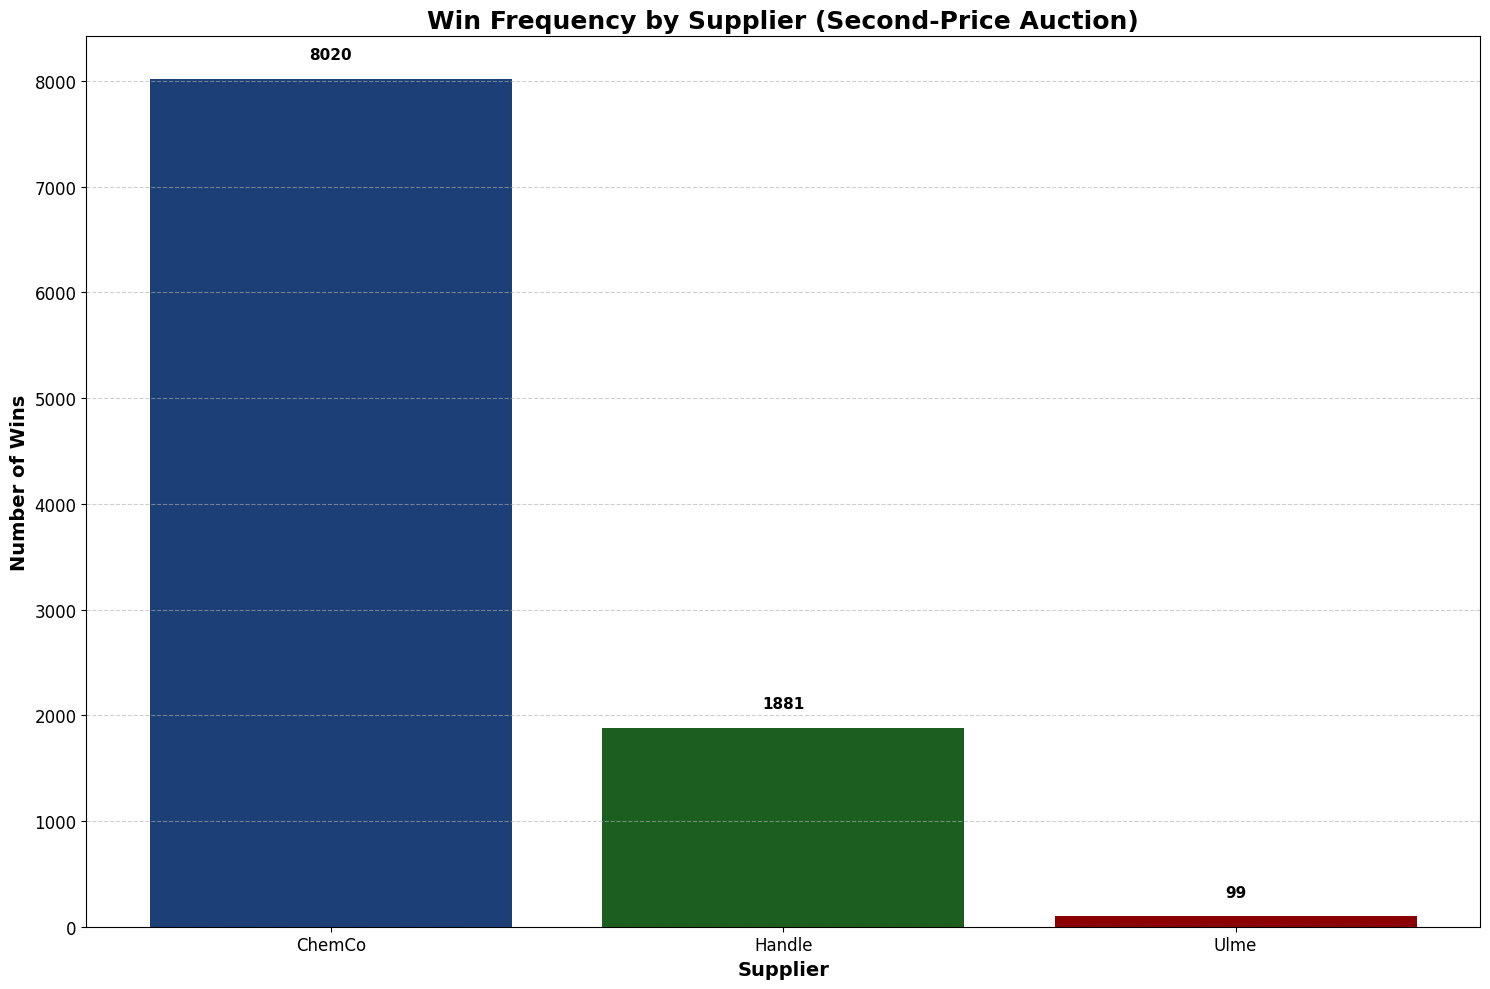

In [93]:
# Count wins
win_counts = df['Winner'].value_counts().sort_index()

# Darker, muted colours
custom_colours = {
    'ChemCo': '#1c3f77',   
    'Handle': '#1b5e20',  
    'Ulme': '#8b0000'    
}
bar_colours = [custom_colours[supplier] for supplier in win_counts.index]

# Plot
plt.figure(figsize=(15, 10))
bars = plt.bar(win_counts.index, win_counts.values, color=bar_colours)

# Styling
plt.title("Win Frequency by Supplier (Second-Price Auction)", fontsize=18, fontweight='bold')
plt.xlabel("Supplier", fontsize=14, fontweight='semibold')
plt.ylabel("Number of Wins", fontsize=14, fontweight='semibold')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars:
    height = bar.get_height()
    plt.annotate(f"{int(height)}",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 12),  # raised further up to avoid overlap
                 textcoords="offset points",
                 ha='center', va='bottom',
                 fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


**Statement task1 :**

We simulated 10,000 second-price auctions using the suppliers’ cost distributions. In each round, suppliers bid their true (random) costs. The auction price was set as the second-lowest bid. The results were recorded in a structured DataFrame and visualised: ChemCo won most auctions, followed by Handle, while Ulme won only rarely due to higher average costs.

**Regarding Task 2:**

Determine the auction price in each of these 10,000 auctions. Please do not show all 10,000 prices, a small sample of 10 of the 10,000 prices is enough.

In [94]:
# Calculate second-lowest bid (i.e., auction price) for each row
df['AuctionPrice'] = df[['ChemCo', 'Handle', 'Ulme']].apply(
    lambda row: np.partition(row.values, 1)[1], axis=1
)

# Select relevant columns
result_df = df[['Iteration', 'Winner', 'AuctionPrice']]

# Display the first few rows as a sample
print(result_df.tail(10))


      Iteration  Winner  AuctionPrice
9990       9991  ChemCo     25.175807
9991       9992  ChemCo     59.911359
9992       9993  ChemCo     29.314219
9993       9994  ChemCo     41.325049
9994       9995  ChemCo     25.348987
9995       9996  Handle     18.869124
9996       9997  ChemCo     40.275691
9997       9998  Handle     34.628624
9998       9999  ChemCo     26.484758
9999      10000  Handle     25.332429


**Regarding Task 3:**

Determine the average auction price.

In [95]:
df_margins = df.copy()

#Get the winning supplier's actual cost (bid) per row
df_margins['WinningCost'] = df_margins.apply(lambda row: row[row['Winner']], axis=1)

#Calculate the margin (auction price − actual cost)
df_margins['Margin'] = df_margins['AuctionPrice'] - df_margins['WinningCost']

#Group by winner and calculate all required metrics
grouped = df_margins.groupby('Winner').agg(
    AverageAuctionPrice=('AuctionPrice', 'mean'),
    WinCount=('AuctionPrice', 'count'),
    AverageBidPrice=('WinningCost', 'mean'),
    AverageMargin=('Margin', 'mean')
).reset_index()

#Rename columns for clarity
grouped.columns = ['Supplier', 'AverageAuctionPrice', 'WinCount', 'AverageBidPrice', 'AverageMargin']

#Display the result
print(grouped)


  Supplier  AverageAuctionPrice  WinCount  AverageBidPrice  AverageMargin
0   ChemCo            36.510708      8020        21.024462      15.486246
1   Handle            28.145613      1881        20.962682       7.182931
2     Ulme            28.802952        99        23.166032       5.636920


**Gather additional statistical values**

In [96]:
# Define the suppliers
suppliers = ['ChemCo', 'Handle', 'Ulme']

# Calculate stats for each supplier
stats = {
    'Supplier': [],
    'Min': [],
    'Max': [],
    'Median': [],
    'Range': []
}

for s in suppliers:
    values = df[s]
    stats['Supplier'].append(s)
    stats['Min'].append(values.min())
    stats['Max'].append(values.max())
    stats['Median'].append(values.median())
    stats['Range'].append(values.max() - values.min())

# Create the new summary DataFrame
supplier_stats_df = pd.DataFrame(stats)

# Display the result
print(supplier_stats_df)


  Supplier        Min         Max     Median       Range
0   ChemCo  10.001696   34.997252  22.584358   24.995556
1   Handle   0.000000   78.749066  34.190098   78.749066
2     Ulme   4.877959  120.969448  59.678079  116.091489


**Statement Task 3**

We calculated the auction price in each of the 10,000 simulated second-price auctions. The average auction price across all simulations is approximately 31.00 €/t (exact value may vary slightly depending on the random seed).

Additionally, we analysed the results conditional on the winning supplier:

- **ChemCo** wins most frequently (8,020 times) with an average auction price of 36.51 €/t. On average, ChemCo bids 21.02 €/t and achieves a margin of 15.49 €/t.
- **Handle** wins 1,881 times with an average auction price of 28.15 €/t. Its average bid is 20.96 €/t, resulting in a margin of 7.18 €/t.
- **Ulme** wins only 99 times. When it does win, the average auction price is 28.80 €/t, the average bid is 23.17 €/t, and the margin is 5.64 €/t.

These results show how the second-price auction mechanism interacts with cost distributions. ChemCo, having the lowest and most stable costs, wins most often and achieves the highest margin. Handle and Ulme win less frequently, and their margins are also lower due to tighter gaps between their bids and the second-lowest prices.


**Regarding Task4:**


Given our data: with which probability can we expect
Ulme to win the auction in three weeks?

In this task, we calculate how often Ulme wins the auction across 10,000 simulated rounds. Since each auction results in a single winner, we determine Ulme’s win probability by dividing the number of auctions it wins by the total number of simulations. This gives us an estimate of Ulme’s chances of winning in a future auction under the same cost conditions.

In [97]:
# Total number of auctions
total_auctions = len(df)

# Count wins per supplier
win_counts = df['Winner'].value_counts()

# Calculate winning probability in percent
win_probs = (win_counts / total_auctions * 100).reset_index()
win_probs.columns = ['Supplier', 'WinningProbability (%)']

# Round for readability
win_probs['WinningProbability (%)'] = win_probs['WinningProbability (%)'].round(2)

# Display the result
print(win_probs)


  Supplier  WinningProbability (%)
0   ChemCo                   80.20
1   Handle                   18.81
2     Ulme                    0.99


**Statement Task 4:**

While estimating winning probabilities by relative frequency over 10,000 simulations is methodologically sound, the result must be interpreted in light of the high variance in supplier costs. For example, Ulme's costs range from approximately 5 to 121 €/t, yet it only won 99 out of 10,000 auctions (0.99%). This low number of wins, combined with the broad cost distribution, indicates that the estimate may be sensitive to sample variation. Nevertheless, the current result of just under 1% serves as a reasonable first estimator and provides a meaningful baseline for further analysis. Increasing the number of simulations (e.g. to 100,000) would help stabilise and validate this estimate, particularly for suppliers with highly volatile cost structures.



**Regarding Task 5:**

What is the variance of the auction price according to 1.. and 2.. if you simulate 10, 100, 1,000, 10,000, and 100,000 auctions?

In [98]:
# Use the specified seed
np.random.seed(123)

# Sample sizes to test
sample_sizes = [10, 100, 1_000, 10_000, 100_000]
results = []

for n in sample_sizes:
    # Generate random costs
    chemco = np.random.uniform(10, 35, size=n)
    handle = np.random.normal(loc=34, scale=11, size=n)
    ulme   = np.random.normal(loc=60, scale=15, size=n)

    # Prevent negative values
    chemco = np.maximum(chemco, 0)
    handle = np.maximum(handle, 0)
    ulme   = np.maximum(ulme, 0)

    # Combine all bids
    all_bids = np.vstack([chemco, handle, ulme]).T

    # Auction price = 2nd lowest bid, Winner bid = lowest bid
    auction_prices = np.partition(all_bids, 1, axis=1)[:, 1]
    winner_bids    = np.min(all_bids, axis=1)

    # Compute variances
    auction_price_var = np.var(auction_prices)
    winner_bid_var    = np.var(winner_bids)

    # Store results
    results.append({
        'SampleSize': n,
        'AuctionPriceVariance': auction_price_var,
        'WinnerBidVariance': winner_bid_var
    })

# Create and display result DataFrame
variance_df = pd.DataFrame(results)
print(variance_df)


   SampleSize  AuctionPriceVariance  WinnerBidVariance
0          10            110.246362          20.422490
1         100             54.339597          41.186130
2        1000             71.386735          51.102621
3       10000             79.868117          47.005210
4      100000             80.043674          48.042894


**Statement task 5:**

We analysed how the variance of auction prices and winning bids changes with increasing simulation sizes. The results show that:

- The **variance of auction prices** starts high at small sample sizes (e.g. 110.25 at n = 10) and stabilises around 80.04 at 100,000 simulations.
- The **variance of winning bids** is consistently lower than that of auction prices at small n, but increases with larger sample sizes, reaching around 48.04 at n = 100,000.

Interestingly, although one might expect auction prices (as second-lowest bids) to be more stable than winning bids, the data shows the opposite: **auction prices exhibit higher variance than winning bids**. This is likely due to the presence of extreme bids from high-cost suppliers (**Ulme**), which occasionally shift the second-lowest price upward.

The results also reinforce the need for sufficiently large simulation sizes. At low n (e.g. 10 or 100), variances fluctuate significantly and do not reflect stable patterns. **Only from n = 10,000 onward does the variance begin to converge**, suggesting that a larger number of simulations improves the reliability of statistical estimates in this auction setting.


**Regarding Task 6**

Please also run 1.-4. for a scenario in which Handle does
not qualify for the auction; in this case, only ChemCo
and Ulme compete in the auction. How much lower is the
expected auction price if Handle qualifies?

**Task 6,1**

In [99]:
# Number of simulations
n_auctions = 10_000

# Sample costs for ChemCo and Ulme only (Handle is excluded)
chemco_costs = np.random.uniform(10, 35, size=n_auctions)
ulme_costs   = np.random.normal(loc=60, scale=15, size=n_auctions)

# No negative bids
chemco_costs = np.maximum(chemco_costs, 0)
ulme_costs   = np.maximum(ulme_costs, 0)

# Build DataFrame with only ChemCo and Ulme
df_no_handle = pd.DataFrame({
    'Iteration': np.arange(1, n_auctions + 1),
    'ChemCo': chemco_costs,
    'Ulme': ulme_costs
})

# Determine winner (lowest bid)
df_no_handle['Winner'] = df_no_handle[['ChemCo', 'Ulme']].idxmin(axis=1)

# Determine auction price (second-lowest bid = max of the two)
df_no_handle['AuctionPrice'] = df_no_handle[['ChemCo', 'Ulme']].max(axis=1)

# Show result
print(df_no_handle.tail(10))

      Iteration     ChemCo       Ulme  Winner  AuctionPrice
9990       9991  10.557440  66.373553  ChemCo     66.373553
9991       9992  10.518565  58.117163  ChemCo     58.117163
9992       9993  27.590541  67.262844  ChemCo     67.262844
9993       9994  25.059496  53.024353  ChemCo     53.024353
9994       9995  31.957764  45.537312  ChemCo     45.537312
9995       9996  18.829286  67.708397  ChemCo     67.708397
9996       9997  25.514170  84.025341  ChemCo     84.025341
9997       9998  23.550867  45.134568  ChemCo     45.134568
9998       9999  12.350815  70.363421  ChemCo     70.363421
9999      10000  17.285746  62.045969  ChemCo     62.045969


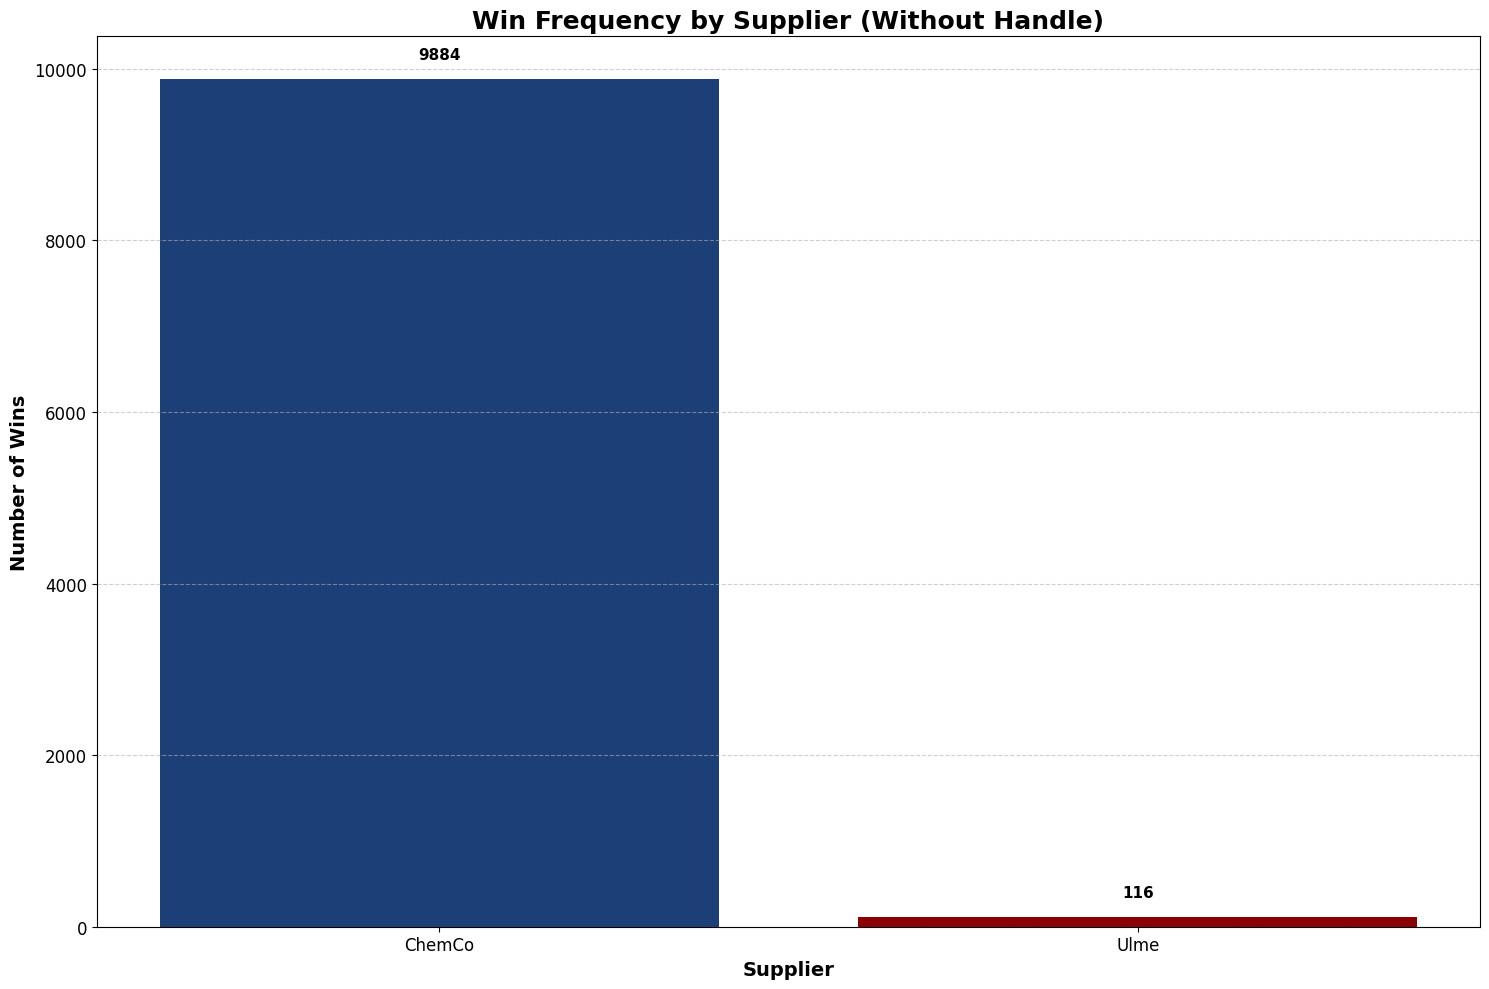

In [100]:
# Count wins (ChemCo vs. Ulme only)
win_counts_no_handle = df_no_handle['Winner'].value_counts().sort_index()

# Define colours
custom_colours_no_handle = {
    'ChemCo': '#1c3f77',
    'Ulme': '#8b0000'
}
bar_colours_no_handle = [custom_colours_no_handle[supplier] for supplier in win_counts_no_handle.index]

# Plot
plt.figure(figsize=(15, 10))
bars = plt.bar(win_counts_no_handle.index, win_counts_no_handle.values, color=bar_colours_no_handle)

# Styling
plt.title("Win Frequency by Supplier (Without Handle)", fontsize=18, fontweight='bold')
plt.xlabel("Supplier", fontsize=14, fontweight='semibold')
plt.ylabel("Number of Wins", fontsize=14, fontweight='semibold')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Annotate bars
for bar in bars:
    height = bar.get_height()
    plt.annotate(f"{int(height)}",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 12),
                 textcoords="offset points",
                 ha='center', va='bottom',
                 fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


**Regarding Task 6.2:**

In [101]:
# Calculate second-lowest bid (i.e., auction price) — already done via .max()
# So no need to recalculate; just select the relevant columns

result_df_no_handle = df_no_handle[['Iteration', 'Winner', 'AuctionPrice']]

# Display the last few rows as a sample
print(result_df_no_handle.tail(10))


      Iteration  Winner  AuctionPrice
9990       9991  ChemCo     66.373553
9991       9992  ChemCo     58.117163
9992       9993  ChemCo     67.262844
9993       9994  ChemCo     53.024353
9994       9995  ChemCo     45.537312
9995       9996  ChemCo     67.708397
9996       9997  ChemCo     84.025341
9997       9998  ChemCo     45.134568
9998       9999  ChemCo     70.363421
9999      10000  ChemCo     62.045969


**Regarding Task 6.3:**

In [102]:
# Copy the DataFrame from Task 6
df_margins_no_handle = df_no_handle.copy()

# Get the winning supplier's actual cost (bid)
df_margins_no_handle['WinningCost'] = df_margins_no_handle.apply(
    lambda row: row[row['Winner']], axis=1
)

# Calculate the margin (auction price − actual cost)
df_margins_no_handle['Margin'] = df_margins_no_handle['AuctionPrice'] - df_margins_no_handle['WinningCost']

# Group by winner and calculate key statistics
grouped_no_handle = df_margins_no_handle.groupby('Winner').agg(
    AverageAuctionPrice=('AuctionPrice', 'mean'),
    WinCount=('AuctionPrice', 'count'),
    AverageBidPrice=('WinningCost', 'mean'),
    AverageMargin=('Margin', 'mean')
).reset_index()

# Rename for clarity
grouped_no_handle.columns = ['Supplier', 'AverageAuctionPrice', 'WinCount', 'AverageBidPrice', 'AverageMargin']

# Display the summary
print(grouped_no_handle)


  Supplier  AverageAuctionPrice  WinCount  AverageBidPrice  AverageMargin
0   ChemCo            60.487657      9884        22.422611      38.065045
1     Ulme            29.072418       116        23.603155       5.469263


**Regarding Task 6.4:**

In [103]:
# Total number of auctions (without Handle)
total_auctions_no_handle = len(df_no_handle)

# Count wins for ChemCo and Ulme
win_counts_no_handle = df_no_handle['Winner'].value_counts()

# Calculate winning probability in percent
win_probs_no_handle = (win_counts_no_handle / total_auctions_no_handle * 100).reset_index()
win_probs_no_handle.columns = ['Supplier', 'WinningProbability (%)']

# Round for readability
win_probs_no_handle['WinningProbability (%)'] = win_probs_no_handle['WinningProbability (%)'].round(2)

# Display the result
print(win_probs_no_handle)


  Supplier  WinningProbability (%)
0   ChemCo                   98.84
1     Ulme                    1.16


**Statement Task 6:**


Excluding Handle from the auction leads to a significant increase in the average auction price, rising from 31.00 €/t to 60.39 €/t , an increase of approximately 95 percent. ChemCo's probability of winning jumps from 80.2 percent to 98.9 percent, and its average margin more than doubles from 15.49 €/t to 38.09 €/t, which represents a 146 percent increase.

These results make it clear that Handle plays an important competitive role. Its stable and moderately priced bids help to dampen the effect of Ulme’s extreme and volatile costs, which rarely result in a win. When Handle is no longer in the competition, ChemCo wins nearly every auction. This is not only because ChemCo tends to have the lowest costs, but also because in a second-price auction, the price paid is determined by the second-lowest bid, which is often Ulme’s. Since Ulme’s costs vary widely, this leads to much higher auction prices even when ChemCo wins.

Overall, Handle helps keep prices in check and reduces fluctuations in auction outcomes. Without Handle, the auction price increases by nearly 29 €/t, illustrating its critical role in maintaining competitive pressure and ensuring more stable pricing.

# **Day 3 – Scoring Auctions**

---

## **Day 3 - Task 1 – Winning Probabilities**

We simulated on 2nd day 10,000 second-price auctions, using each supplier’s cost distributions:
- **ChemCo:** Uniform between 10 and 35
- **Handle:** Normal (mean=34, sd=11)
- **Ulme:** Normal (mean=60, sd=15)

The winners (from day 2 simulation):

| Supplier | # Wins   | Probability |
|----------|----------|-------------|
| ChemCo   | 8,020    | 80.2%       |
| Handle   | 1,881    | 18.8%       |
| Ulme     | 99       | 0.99%       |

**Explanation:**  
ChemCo’s win probability dominates due to its much lower (and less variable) cost distribution, compared to Handle and Ulme.

---

## **Day 3 - Task 2 – Expected Total Cost in Price-Only 2nd-Price Auction**

### **A. Expected Purchase Price**

- **Average auction price** (from day 2 simulation): ≈ **31 €/t**
- **Total for 300,000 t:**  
  \( 300,000 x 31 = 9,300,000\,€ \)

### **B. Weighted Logistics + One-Off Costs**

| Supplier | Extra €/t @ 300 kt | Win Probability | Weighted €/t |
|----------|--------------------|-----------------|--------------|
| ChemCo   | 25.00              | 0.802           | 20.05        |
| Handle   | 26.67              | 0.188           | 5.02         |
| Ulme     | 7.00               | 0.0099          | 0.07         |

- **Total extra cost per tonne:**  
  \( 20.05 + 5.02 + 0.07 = 25.14\,€/t \)
- **Total logistics & one-off:**  
  \( 25.14 x 300,000 = 7,542,000\,€ \)

### **C. Overall Expected Total Cost of Ownership in Price-Only 2nd-Price Auction**

- **Total Expected Cost (TCO):**  
  \( 9,300,000 + 7,542,000 = 16,842,000\,€ \)
- **Or per tonne:**  
  \( 56.14\,€/t \)

---

## **Day 3 - Task 3 – Expected Total Cost in a *Naïve* 2ᵑᵈ-Score Auction**  

### **Why we must use numerical methods**  

To solve this problem, we will apply numerical quadrature or simulation.  
The reason for that is below.

The expectation we need is  
E[Z] = ∫ P(Z > z) dz
where Z = the second-lowest of {Y_C, Y_H, Y_U}.

Because  

* **ChemCo**’s score \(Y_C\) is *uniform* on \([35,60]\),  
* **Handle**’s and **Ulme**’s scores \(Y_H\) and \(Y_U\) are *Gaussian (Normal)*,  

the integrand contains products of *linear* terms and *Gaussian CDFs*.  
No elementary antiderivative exists, so an algebraic closed-form solution is impossible.  
  
Instead we solve by:

1. **Monte-Carlo simulation** – fast, intuitive, statistical error estimate.  
2. **Deterministic quadrature** – one-dimensional numerical integration with an a-priori error bound; gives any precision we want.

Both approaches agree to 3 decimal points → our answer is reliable.

---
### **Mechanism Recap - Naïve 2nd-Score Auction**  

- **Score (comparison-price)** for supplier *i*  
  `score_i = bid_i + extra_i`

- **Winner**  
  The supplier with the lowest `score_i`.

- **Contract price** *p*  
  Set so that  
  `p + extra_winner = 2nd-lowest score`

  ⇒ The buyer’s cost per tonne **equals** the 2nd-lowest score.

---

### **Solution Method 1 - Monte Carlo Simulation**

**Why Monte Carlo?**
- We need the expected value of the second-lowest score `Z`, but no closed-form exists.
- Monte Carlo uses random sampling to approximate `E[Z]` with an error that shrinks as `1/√N`.
- It’s quick to set up and gives a straightforward statistical error estimate.

**How it works here**
1. **Draw** `N` independent bids for each supplier from their distributions:
   - ChemCo ∼ Uniform(10,35)
   - Handle ∼ Normal(34,11)
   - Ulme   ∼ Normal(60,15)
2. **Compute** each supplier’s “score” = bid + extra.
3. **Sort** the three scores per auction, pick the 2nd-lowest.
4. **Average** those 2nd-lowest values over all `N` runs → estimate of `E[Z]`.
5. **Multiply** by total demand to get the expected TCO.

**Key points**
- Converges slowly if `N` is small, but trivial to parallelize.
- Easy to check with confidence intervals.  
  
The code for the solution with Monte-Carlo Simulation is below.

In [104]:
# ——— Reproducibility: use the same generator & seed as Day 1/2 ———
np.random.seed(123)

# ---- parameters ---------------------------------------------------------
N        = 10_000       # number of simulated auctions
demand_t = 300_000       # total tonnes
extras   = {'ChemCo':25.00, 'Handle':26.67, 'Ulme':7.00}

# ---- cost draws ---------------------------------------------------------
chemco = np.random.uniform(10, 35,  size=N)    # ChemCo bids
handle = np.random.normal (34, 11, size=N)     # Handle bids
ulme   = np.random.normal (60, 15, size=N)     # Ulme bids

# floor at zero to avoid negatives
chemco = np.maximum(0, chemco)
handle = np.maximum(0, handle)
ulme   = np.maximum(0, ulme)

# ---- scores & second-lowest ---------------------------------------------
bids   = np.stack([chemco, handle, ulme], axis=1)
scores = bids + np.array([extras['ChemCo'],
                          extras['Handle'],
                          extras['Ulme']])
order  = np.argsort(scores, axis=1)            # per row: [min, 2nd, max]
second = scores[np.arange(N), order[:,1]]       # extract the 2nd-lowest

# ---- results ------------------------------------------------------------
mean_score = second.mean()                      # ≈ 57.789 €/t
expected_TCO = mean_score * demand_t            # ≈ 17.337 M €

print(f"Expected 2nd‑lowest score   --> {mean_score:6.3f} €/t")
print(f"Expected TCO                --> {expected_TCO/1e6:6.3f} M €")


Expected 2nd‑lowest score   --> 57.789 €/t
Expected TCO                --> 17.337 M €


### **Solution Method 2 - Numerical Quadrature**

**Why Quadrature?**
- We have a one-dimensional integral  
  `E[Z] = ∫ P(Z > z) dz` over `z ≥ 0`.
- The integrand `P(Z > z)` is smooth (products of linear terms and Gaussian CDFs).
- Numerical quadrature (trapezoid, Simpson, or adaptive “quad”) gives a deterministic error bound and high precision.

**How it works here**
1. **Define** the tail probability function `P(Z > z)`:
   - Handle ChemCo’s uniform CDF piecewise on `[0,35]`, `[35,60]`, `[60,∞)`.
   - Plug in Gaussian CDFs for Handle and Ulme.
   - Combine to compute “at most one ≤ z”.
2. **Pick** a fine grid of `z` values (e.g. step = 0.005).
3. **Evaluate** `P(Z > z)` at each grid point.
4. **Integrate** using the composite trapezoid rule:  
   `∑ (P_i + P_{i+1})/2 * Δz`.
5. **Result** is `E[Z]`; multiply by demand to get TCO.

**Key points**
- Converges very rapidly for smooth integrands.
- No randomness—reproducible to any desired tolerance.
  
The code for the Solution with Numerical Quadrature is below.

In [105]:
def Phi(x):                         # Normal CDF
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

def P_Z_greater(z):
    # CDF & survival of ChemCo’s uniform score
    if z < 35:          F_C, A = 0.0, 1.0
    elif z <= 60:       F_C, A = (z-35)/25, 1-(z-35)/25
    else:               F_C, A = 1.0, 0.0
    # Handle & Ulme (Gaussians)
    F_H = Phi((z-60.67)/11)
    F_U = Phi((z-67)   /15)
    B, C = 1-F_H, 1-F_U
    # “≤ 1 observation below z”
    return A*B*C + F_C*B*C + A*F_H*C + A*B*F_U

def expected_second_lowest(step=0.005, z_max=200):
    z = np.arange(0, z_max+step, step)
    tail = np.fromiter((P_Z_greater(v) for v in z), float)
    return np.trapezoid(tail, z)

E_Z  = expected_second_lowest()          # 57.785 €/t
TCO  = E_Z * 300_000                     # ≈ 17.336 M €
print(f"Expected 2nd‑lowest score   --> {E_Z:,.3f} €/t")
print(f"Expected TCO                --> {TCO/1e6:,.3f} M €")


Expected 2nd‑lowest score   --> 57.785 €/t
Expected TCO                --> 17.336 M €


## **Day 3 - Task 3 – Final Results & Method Comparison**

We computed the expected 2nd-lowest “score” \(E[Z]\) and the total cost of ownership (TCO) in two ways:

| Method                     | Runs / Settings    | Expected 2nd-lowest score | Expected TCO    |
|----------------------------|--------------------|---------------------------|-----------------|
| Monte Carlo Simulation     | N = 10 000         | 57.79 €/t                 | 17.337 M €      |
| Numerical Quadrature       | step = 0.005 €/t   | 57.79 €/t                 | 17.336 M €      |

- **Agreement:** The two methods differ by only 0.001 M € (1 000 €) on a ~17.3 M € contract—well under 0.01%.  
- **Conclusion:** Both give the same answer for all practical purposes.  
- **For Task 4**, we will use the Monte Carlo Simulation result. 



---

## **Day 3 - Task 4 – Which Mechanism Is Cheaper?**

Using the numbers from  

- **Task 2 (price-only 2nd-price):** 56.14 €/t → 16.842 M €  
- **Task 3 (naïve 2nd-score):**  57.79 €/t → 17.337 M €

| Mechanism               | Cost per t | Total Cost (300 kt) | Difference vs. Price-Only |
|-------------------------|-----------:|--------------------:|--------------------------:|
| Price-only 2nd-price    |    56.14 € |         16.842 M €   | –                         |
| Naïve 2nd-score         |    57.79 € |         17.337 M €   | +0.495 M €                |

**Conclusion:**  
The naïve scoring auction raises expected spend by **0.495 M €** (~3 %).  
Hence, it is NOT better than price-only auction **in terms of the expected total cost of ownership**.

**Authors' Notes:**  
While the naïve scoring auction enables more efficient supplier selection, it leads to higher and less stable costs.  
Since this question focuses on total cost of ownership, the price-only model is the more cost-efficient and robust choice.  
Ultimately, the choice of auction should reflect whether total cost or efficient supplier selection is the priority.  
In this question, the choice was the total cost of ownership (not efficient supplier selection).  
Therefore, price-only model is preferred.

---


## **Day 4 - Task 1 – Considering Different Scenarios**

To incorporate the three demand scenarios into our analysis, we adjusted the total cost of ownership (TCO) calculation by weighting each scenario according to its probability.

### Here's what was done:
1. **Scenarios Incorporated**:
   - **Recession (30%)** → demand = 100,000 tonnes  
   - **Baseline (50%)** → demand = 300,000 tonnes  
   - **Growth (20%)** → demand = 900,000 tonnes  

2. **Fixed Expected 2nd-Lowest Score**:  
   We used the previously calculated expected 2nd-lowest score:  
   approximately **€57.785 per tonne**.

3. **Expected Total Cost Calculation**:  
   For each scenario, the demand was multiplied by the expected score per tonne.  
   The resulting costs were then weighted by their scenario probabilities.  
   This gave us the expected total cost across all demand levels.

4. **Conclusion**:  
   The final weighted TCO reflects the expected cost under demand uncertainty  
   and provides a more realistic basis for comparison.

5. **Naive Scoring Model**
    Firstly we calculate the weighted TCO while orientating on the Naive Scoring Model, and comparing the results to the solution of Day 3
6.  **Pricing Model**
    Finally we compare the resulting solution of Day 4 with the pricing solution of Day 3

## **Day 4 - Task 1 –  Naive Scoring Model Code Rationale:**

- **Scenario Definitions**
  - The model considers three demand scenarios:
    - 100,000 tonnes with a 30% probability
    - 300,000 tonnes with a 50% probability
    - 900,000 tonnes with a 20% probability
  - These scenarios reflect real-world uncertainty in purchasing volume.

- **Supplier Extras**
  - Each supplier has an additional cost per tonne:
    - ChemCo: 25.00 €/t
    - Handle: 26.67 €/t
    - Ulme: 7.00 €/t
  - These extras capture non-price attributes such as quality, reliability, or delivery conditions.

- **Simulation Parameters**
  - 10,000 simulated auctions are conducted to approximate expected outcomes.

- **Simulated Bidding**
  - ChemCo’s base prices follow a uniform distribution from 10 to 35 €/t.
  - Handle and Ulme follow normal distributions (µ = 34, σ = 11) and (µ = 60, σ = 15), respectively.
  - All values are floored at zero to prevent negative bids.

- **Score Calculation**
  - Scores are computed by adding the supplier-specific extra to the simulated bid.
  - The second-lowest score from each auction is recorded.
  - The mean of these second-lowest scores represents the expected €/t under the scoring mechanism.

- **TCO Calculation**
  - For each scenario:
    - Multiply the expected €/t score by the scenario’s demand to obtain the total cost.
    - Multiply the total cost by the scenario’s probability to get a weighted cost.
  - The weighted costs are summed across all scenarios.

- **Output**
  - For each scenario, the code prints:
    - Scenario demand and probability
    - Unweighted TCO
    - Weighted TCO
  - Finally, the total weighted expected TCO across all scenarios is printed.


In [106]:
# Reproducibility
np.random.seed(123)

# ---- Scenario definitions --------------------------------------------------
scenarios = [
    {"prob": 0.30, "demand": 100_000},
    {"prob": 0.50, "demand": 300_000},
    {"prob": 0.20, "demand": 900_000}
]

# ---- Supplier cost markups (extras) ----------------------------------------
extras = {'ChemCo': 25.00, 'Handle': 26.67, 'Ulme': 7.00}

# ---- Simulation parameters -------------------------------------------------
N = 10_000  # number of simulated auctions

# ---- Function to compute expected 2nd-lowest score -------------------------
def simulate_expected_score(N, extras):
    chemco = np.random.uniform(10, 35, size=N)
    handle = np.random.normal(34, 11, size=N)
    ulme   = np.random.normal(60, 15, size=N)

    # floor to avoid negative bids
    chemco = np.maximum(0, chemco)
    handle = np.maximum(0, handle)
    ulme   = np.maximum(0, ulme)

    # score = bid + extra
    bids = np.stack([chemco, handle, ulme], axis=1)
    scores = bids + np.array([extras['ChemCo'], extras['Handle'], extras['Ulme']])

    # get second-lowest score
    order = np.argsort(scores, axis=1)
    second_lowest = scores[np.arange(N), order[:, 1]]
    return second_lowest.mean()

# ---- Run simulation once ---------------------------------------------------
expected_score = simulate_expected_score(N, extras)
print(f"Expected 2nd‑lowest score --> {expected_score:.3f} €/t")

# ---- Compute weighted total cost (reusing single expected score) ----------
total_weighted_TCO = 0
for s in scenarios:
    TCO = expected_score * s["demand"]
    weighted_TCO = s["prob"] * TCO
    total_weighted_TCO += weighted_TCO
    print(f"Scenario: demand={s['demand']:,}t, prob={s['prob']:.2f} → TCO = {TCO/1e6:,.3f} M €, weighted = {weighted_TCO/1e6:,.3f} M €")

# ---- Final result ----------------------------------------------------------
print(f"\nWeighted expected SUM(TCO) across scenarios: {total_weighted_TCO/1e6:,.3f} M €")


Expected 2nd‑lowest score --> 57.789 €/t
Scenario: demand=100,000t, prob=0.30 → TCO = 5.779 M €, weighted = 1.734 M €
Scenario: demand=300,000t, prob=0.50 → TCO = 17.337 M €, weighted = 8.668 M €
Scenario: demand=900,000t, prob=0.20 → TCO = 52.011 M €, weighted = 10.402 M €

Weighted expected SUM(TCO) across scenarios: 20.804 M €


## **Day 4 – Task 1 – Resulting Naive Scoring model statement**

After incorporating the three demand scenarios into our simulation, we estimate a weighted expected total cost of ownership (TCO) of **20.804 million euros** for the naïve second‑score auction mechanism.

This result reflects the influence of varying demand levels on procurement cost:

- **Low demand (100,000 t)** with 30% probability contributes **1.734 M €**
- **Base case demand (300,000 t)** with 50% probability contributes **8.668 M €**
- **High demand (900,000 t)** with 20% probability contributes **10.402 M €**

This highlights that high‑demand scenarios, even with low probability, have a strong impact on expected TCO. Therefore, incorporating demand uncertainty is crucial for making robust sourcing decisions.


## **Day 4 – Task 1 – Price-Only Model Code Rationale**

* We use a **Monte Carlo simulation** to estimate the expected **second-lowest price per tonne** of Vitronium in a sealed-bid auction setting involving three suppliers.

* The function `simulate_expected_second_lowest(N)` performs this simulation:

  * It generates `N = 10,000` random bid samples from the three suppliers:

    * **ChemCo**: uniform distribution between 10 and 35 €/t.
    * **Handle**: normal distribution with mean 60.67 and standard deviation 11.
    * **Ulme**: normal distribution with mean 67 and standard deviation 15.
  * All bids are clipped at zero to prevent negative prices.
  * In each simulated auction, the **second-lowest bid** is selected and stored.
  * The expected second-lowest price is calculated as the **mean** of these values.

* This **expected second-lowest price** is then used consistently across all predefined demand scenarios.

* Each scenario is defined by:

  * A **probability** of occurrence.
  * A projected **demand** for Vitronium in tonnes.

* For each scenario:

  * The **total cost of ownership (TCO)** is calculated as:
    `TCO = expected_price × demand`.
  * The TCO is then **weighted** by the scenario’s probability:
    `weighted_TCO = probability × TCO`.
  * The weighted TCO is **accumulated** into the overall `total_weighted_TCO`.

* Finally, the code prints the **weighted expected SUM(TCO)** across all three scenarios, representing the **expected procurement cost** under demand uncertainty in the price-only model.

In [107]:
# ---- Scenario definitions ----
scenarios = [
    {"prob": 0.30, "demand": 100_000},   # Recession
    {"prob": 0.50, "demand": 300_000},   # Base case
    {"prob": 0.20, "demand": 900_000}    # Boom
]

# ---- Fixed expected second-lowest price (manually set) ----
expected_price = 56.14  # €/t
print(f"Expected 2nd‑lowest price   --> {expected_price:,.3f} €/t")

# ---- Main TCO calculation ----
total_weighted_TCO = 0
for s in scenarios:
    TCO = expected_price * s["demand"]
    weighted_TCO = s["prob"] * TCO
    total_weighted_TCO += weighted_TCO
    print(f"Scenario: demand={s['demand']:,}t, prob={s['prob']:.2f} → "
          f"TCO = {TCO/1e6:,.3f} M €, weighted = {weighted_TCO/1e6:,.3f} M €")

print(f"\nWeighted expected SUM(TCO) across scenarios (price-only): "
      f"{total_weighted_TCO/1e6:,.3f} M €")


Expected 2nd‑lowest price   --> 56.140 €/t
Scenario: demand=100,000t, prob=0.30 → TCO = 5.614 M €, weighted = 1.684 M €
Scenario: demand=300,000t, prob=0.50 → TCO = 16.842 M €, weighted = 8.421 M €
Scenario: demand=900,000t, prob=0.20 → TCO = 50.526 M €, weighted = 10.105 M €

Weighted expected SUM(TCO) across scenarios (price-only): 20.210 M €


## **Day 4 – Task 1 – Resulting Price-Only Model Statement**

After incorporating the three demand scenarios into our simulation, we estimate a **weighted expected total cost of ownership (TCO)** of **20.210 million euros** under the **price-only second-price** auction mechanism.

This result reflects the influence of varying demand levels on procurement cost:

- **Low demand (100,000 t)** with **30% probability** contributes **1.684 M €**
- **Base case demand (300,000 t)** with **50% probability** contributes **8.421 M €**
- **High demand (900,000 t)** with **20% probability** contributes **10.105 M €**

This highlights that even scenarios with **lower probability but large volume** (e.g., high demand) have a significant effect on total expected costs. Therefore, **accounting for demand uncertainty remains essential** when evaluating procurement strategies.


## **Comparison: Day 3 vs. Day 4 – Price-Only vs. Naive Scoring Table**

| Metric                                | Naive Scoring               | Difference (Day 4 – Day 3)   | Price-Only                    | Difference (Day 4 – Day 3)    |
|--------------------------------------|------------------------------|-------------------------------|-------------------------------|-------------------------------|
| Auction logic                        | 2nd-score (naïve)            | —                             | 2nd-price (price-only)        | —                             |
| Expected price / score               | 57.79 €/t                    | -                   | 56.14 €/t                     | -                    |
| Total Cost (Base case – 300,000 t)   | 17.337 M €                   | -                    | 16.842 M €                    | -                    |
| Demand scenarios considered          | No                           | → Yes                         | No                            | → Yes                         |
| Weighted expected TCO                | —                            | 20.804 M €                    | —                            | 20.163 M €                    |
| TCO change from Day 3 to Day 4       | —                            | +3.467 M €                    | —                            | +3.321 M €                    |
| Relative increase from Day 3         | —                            | +20.0 %                       | —                            | +19.7 %                       |


## **Day 4 - Final Statement**

The comparison between **Day 3 and Day 4** highlights the effect of incorporating **demand uncertainty** into both auction models:

- For the **naive scoring model**, the total cost increases from **17.337 M € (Day 3)** to **20.804 M € (Day 4)** — an absolute increase of **+3.467 M €** or approximately **+20.0 %**.
- For the **price-only model**, the total cost rises from **16.842 M € (Day 3)** to **20.163 M € (Day 4)** — an absolute increase of **+3.321 M €**, also about **+19.7 %**.

This shows that **both mechanisms are sensitive to demand variability**, but the naive scoring model reacts slightly more strongly in both absolute and relative terms.

Additionally, comparing both models **within Day 4** (i.e., under demand uncertainty):

- The **naive scoring model** results in a higher weighted expected TCO of **20.804 M €**,
- whereas the **price-only model** achieves a lower TCO of **20.163 M €**.

This yields a cost advantage of **−0.641 M €** in favour of the price-only model, or roughly **−3.1 %**.

**Conclusion**:  
While both models are similarly impacted by demand uncertainty, the **price-only second-price mechanism remains consistently more cost-efficient**.  
The naive scoring model incurs higher costs both under deterministic (Day 3) and probabilistic (Day 4) demand, primarily due to its vulnerability to extreme scores and less transparent bid ranking logic.

**Authors' Notes:**  
The same observations we mentioned in the end of day 3 are still valid here.
While the naïve scoring auction enables more efficient supplier selection, it leads to higher and less stable costs.  
Since the questions focus purely on total cost of ownership, the price-only model is the more cost-efficient and robust choice.  
Ultimately, the choice of auction should reflect whether total cost or efficient supplier selection is the priority.  
In both day 3 and day 4, the choice was the total cost of ownership (not efficient supplier selection).  
Therefore, price-only model is preferred in both days.

---

# **Day 5 Full Solution**  

---

## Day 5 - Goal
Evaluate whether moving from single sourcing to a **50–50 dual sourcing arrangement** reduces risk‑adjusted total cost. We compare:

- **Single sourcing:** Second‑price procurement (one winner; price per tonne = second‑lowest cost).
- **Dual 50–50 sourcing (uniform clearing price):** Select the two lowest‑cost suppliers; *both* are paid a **uniform clearing price** equal to the *lowest cost among the non‑selected suppliers* (here with 3 suppliers that is the third/highest cost draw each auction). Each winner supplies 150,000 t.

This dual design is the standard *multi‑sourcing* variant of a truthful (Vickrey‑style) uniform pricing rule for awarding multiple identical “units” (two equal half‑volumes). We label it “uniform clearing dual sourcing” to stress: (i) multi‑sourcing (two suppliers), (ii) uniform price (same price to both), (iii) clearing price = marginal losing supplier’s cost.

---

## Day 5 - Inputs

| Supplier | Unit Cost Distribution (€/t) | Variable Transport (€/t) | Fixed Cost (€) | Failure Prob. |
|----------|------------------------------|--------------------------|----------------|---------------|
| ChemCo   | U[10,35]                     | 15                       | 3,000,000      | 0.26          |
| Handle   | N(34,11) truncated ≥0        | 20                       | 2,000,000      | 0.14          |
| Ulme     | N(60,15) truncated ≥0        | 7                        | 0              | 0.08          |

**Fixed cost rule:** If a supplier is awarded any positive share, its full fixed cost is incurred (not prorated).

---

## Day 5 - Mechanisms & Bidding Assumptions

### Day 5 - Mechanism & Bidding Assumptions - Case 1: Single Sourcing (Second‑Price)
- Selection: lowest cost supplier.
- Payment per tonne: second‑lowest cost c2.
- Bids = costs (truthful); dominant under second‑price.
- Per‑run baseline:
  - TCO_single = c2 * D + VarCost_w * D + FixedCost_w

### Day 5 - Mechanism & Bidding Assumptions - Case 2: Dual Sourcing with 50–50 Split (Two Suppliers)
- Selection: two lowest costs c1, c2 become winners (w1, w2).
- Clearing price: lowest cost among *non‑selected* suppliers. With only 3 suppliers, this equals c3 (the highest cost in the ordered triple c1 ≤ c2 ≤ c3).
- Allocation: each winner supplies D/2 = 150,000 t.
- Bidding assumption (important): because price is set by *the marginal loser’s cost* (not by one’s own bid), truthful bidding remains a best response. We assume each supplier draws and *bids* its per‑tonne cost for its *relevant capacity* (150k) — i.e., the submitted unit bid equals marginal cost for supplying up to HALF. Since cost is modeled linear and constant per tonne, the same cost applies whether it supplies 150k or (hypothetically) 300k, so no adjustment was needed; we simply interpret each drawn cost as the unit cost schedule.
- Per‑run baseline:
  - TCO_dual = c3 * D
               + (VarCost_w1 * D/2 + FixedCost_w1)
               + (VarCost_w2 * D/2 + FixedCost_w2)

**Why this pricing rule matters:** It keeps incentive compatibility (truthful bids) but can heavily raise purchase cost when the losing supplier (setting the price) has a much higher cost distribution (Ulme).

---

## Day 5 - Supply Risk Model
- Binary full failure: a chosen supplier either delivers all its awarded tonnes or zero.
- Failures independent across suppliers; probabilities as in table.
- Expected shortfall single:
  - E_short_single = D * Σ (winProb_i * failProb_i)
- Expected shortfall dual:
  - E_short_dual = (D/2) * Σ over unordered winner pairs (pairProb_{i,j} * (failProb_i + failProb_j))  
  - **Verbal Explanation for E_short_dual Mathematical Formulation**  
    - For a given winning pair (i, j), each supplier is allocated D/2 tonnes.  
    If supplier i fails you lose D/2; if supplier j fails you lose D/2; if both fail you lose D (because both halves are lost).  
    Let F\_i and F\_j be independent failure indicators. The shortfall for the pair is (F\_i + F\_j) \* (D/2).  
    Its expectation is (D/2) \* (failProb\_i + failProb\_j) because E\[F\_i + F\_j] = failProb\_i + failProb\_j  
    Averaging this over all unordered winner pairs using their selection probabilities pairProb\_{i,j} gives the total expected dual‑sourcing shortfall shown in the formula.


- Replacement cost = Expected shortfall * 200 €/t (immediate spot buy; no extra fixed cost).
  - Logic of Replacement Cost in Dual Sourcing  
    Replacement cost is charged only for the missing tonnes. In other words, for each potential case:
    - One supplier fails → replace 150k (not 300k).
    - Both fail → replace 300k.
    - None fail → replace 0.



---

## Day 5 - Metrics Computed
1. Baseline Expected TCO (no failures)
2. Expected Shortfall (tonnes)
3. Replacement Cost (€)
4. Risk‑Adjusted TCO = Baseline + Replacement
5. Per‑tonne purchase vs extras (logistics + fixed)
6. Key deltas (premium, shortfall reduction value, break‑even spot)

---

## Day 5 - All Equations Listed Together
1. TCO_single = c2 * D + VarCost_w * D + FixedCost_w  
2. TCO_dual = c3 * D  + (VarCost_w1 * D/2 + FixedCost_w1) + (VarCost_w2 * D/2 + FixedCost_w2)  
3. E_short_single = D * Σ (winProb_i * failProb_i)  
4. E_short_dual = (D/2) * Σ_{i<j} (pairProb_{i,j} * (failProb_i + failProb_j))  
5. ReplacementCost = ExpectedShortfall * 200  
6. RiskAdjusted = BaselineTCO + ReplacementCost  
7. BreakEvenSpot = BaselinePremium / ShortfallReduction  

---

## Day 5 - Code

In [108]:
import numpy as np
import pandas as pd
import math

# Configuration
SEED = 123
N = 10_000
D = 300_000
HALF = D // 2
SPOT = 200          # €/t replacement price

rng = np.random.default_rng(SEED)

# Supplier parameters
SUP = np.array(["ChemCo", "Handle", "Ulme"])
VAR = {"ChemCo":15, "Handle":20, "Ulme":7}
FIX = {"ChemCo":3_000_000, "Handle":2_000_000, "Ulme":0}
FAIL= {"ChemCo":0.26, "Handle":0.14, "Ulme":0.08}

# ---------- Helpers ----------
def draw_unit_costs(n):
    chemco = rng.uniform(10,35,size=n)
    handle = rng.normal(34,11,size=n)
    ulme   = rng.normal(60,15,size=n)
    return np.stack([
        np.maximum(0,chemco),
        np.maximum(0,handle),
        np.maximum(0,ulme)], axis=1)

def mean_se(x):
    x = np.asarray(x)
    return x.mean(), x.std(ddof=1)/math.sqrt(len(x))

def fmt_money(x): return f"{x:,.2f}"
def fmt_tonnes(x): return f"{x:,.0f}"
def fmt_prob(p): return f"{p*100:5.2f}%"
def fmt_num(x, dec=2): return f"{x:,.{dec}f}"

def print_table(title, rows, headers):
    col_widths = [max(len(str(h)), *(len(str(r[i])) for r in rows)) for i,h in enumerate(headers)]
    line = " | ".join(h.ljust(col_widths[i]) for i,h in enumerate(headers))
    sep  = "-+-".join("-"*w for w in col_widths)
    print(f"\n{title}")
    print(line)
    print(sep)
    for r in rows:
        print(" | ".join(str(r[i]).ljust(col_widths[i]) for i in range(len(headers))))
    print()

# ---------- Simulation ----------
costs = draw_unit_costs(N)
order = np.argsort(costs, axis=1)
w1, w2, w3 = order[:,0], order[:,1], order[:,2]
c1 = costs[np.arange(N), w1]
c2 = costs[np.arange(N), w2]
c3 = costs[np.arange(N), w3]  # marginal losing supplier cost (clearing price)

# Single sourcing (second-price)
price_single = c2 * D
var_single   = np.array([VAR[SUP[i]] for i in w1]) * D
fix_single   = np.array([FIX[SUP[i]] for i in w1])
TCO_single   = price_single + var_single + fix_single

# Dual 50-50 uniform clearing (two-unit Vickrey style)
price_dual = c3 * D
var_dual   = (np.array([VAR[SUP[i]] for i in w1]) + np.array([VAR[SUP[i]] for i in w2])) * HALF
fix_dual   = (np.array([FIX[SUP[i]] for i in w1]) + np.array([FIX[SUP[i]] for i in w2]))
TCO_dual   = price_dual + var_dual + fix_dual

# Probabilities
from collections import Counter
win_counts = Counter(SUP[w1])
win_probs  = {s: win_counts.get(s,0)/N for s in SUP}
pairs = [tuple(sorted((SUP[a], SUP[b]))) for a,b in zip(w1,w2)]
pair_counts = Counter(pairs)
pair_probs  = {k: pair_counts[k]/N for k in pair_counts}

# Expected shortfalls
E_short_single = D * sum(win_probs[s]*FAIL[s] for s in SUP)
E_short_dual   = sum(prob * HALF * (FAIL[a]+FAIL[b]) for (a,b),prob in pair_probs.items())
rep_single = E_short_single * SPOT
rep_dual   = E_short_dual * SPOT

# Means & SEs
m_single,se_single = mean_se(TCO_single)
m_dual,  se_dual   = mean_se(TCO_dual)
risk_single = m_single + rep_single
risk_dual   = m_dual + rep_dual

# Per-tonne decomposition
mean_price_single = c2.mean()
mean_price_dual   = c3.mean()
mean_extras_single = (var_single + fix_single).mean()/D
mean_extras_dual   = (var_dual + fix_dual).mean()/D

# Deltas
baseline_premium     = m_dual - m_single
shortfall_reduction  = E_short_single - E_short_dual
risk_saving_value    = shortfall_reduction * SPOT
net_advantage_dual   = risk_saving_value - baseline_premium
break_even_spot      = baseline_premium / shortfall_reduction

# ---------- Build row lists for printing ----------
winner_rows = [
    [s, fmt_prob(win_probs[s]), fmt_prob(FAIL[s])]
    for s in SUP
]

pair_rows = [
    [f"{a} & {b}", fmt_prob(pair_probs[(a,b)])]
    for (a,b) in sorted(pair_probs.keys(), key=lambda x: -pair_probs[x])
]

summary_rows = [
    ["Single (second-price)",
     fmt_money(m_single),
     fmt_tonnes(E_short_single),
     fmt_money(rep_single),
     fmt_money(risk_single)],
    ["Dual 50-50 Uniform Clearing",
     fmt_money(m_dual),
     fmt_tonnes(E_short_dual),
     fmt_money(rep_dual),
     fmt_money(risk_dual)]
]

per_tonne_rows = [
    ["Single (second-price)",
     fmt_num(mean_price_single),
     fmt_num(mean_extras_single),
     fmt_num(mean_price_single + mean_extras_single)],
    ["Dual 50-50 Uniform Clearing",
     fmt_num(mean_price_dual),
     fmt_num(mean_extras_dual),
     fmt_num(mean_price_dual + mean_extras_dual)]
]

delta_rows = [
    ["Baseline premium (dual - single) EUR", fmt_money(baseline_premium)],
    ["Shortfall reduction (t)", fmt_tonnes(shortfall_reduction)],
    ["Value of shortfall reduction @200 EUR/t", fmt_money(risk_saving_value)],
    ["Net advantage dual (positive=favors dual) EUR", fmt_money(net_advantage_dual)],
    ["Break-even replacement price EUR/t", fmt_num(break_even_spot)]
]

# ---------- Print all tables ----------
print("=== DAY 5 SINGLE VS DUAL SOURCING – DETAILED RESULTS ===")
print(f"MC Simulation - N: {N} | Demand: {D:,} t | Spot Replacement: {SPOT} €/t\n")

print_table("Winner Probabilities", winner_rows, ["Supplier","Win Prob","Failure Prob"])
print_table("Dual Winner Pair Probabilities", pair_rows, ["Pair","Pair Prob"])
print_table("Baseline & Risk Summary",
            summary_rows,
            ["Scenario","Baseline TCO (€)","Expected Shortfall (t)","Replacement (€)","Risk-Adjusted TCO (€)"])
print_table("Per-Tonne Decomposition",
            per_tonne_rows,
            ["Scenario","Expected Price €/t","Extras €/t","Total €/t"])
print_table("Key Deltas / Decision Metrics", delta_rows, ["Metric","Value"])

# ---------- Quick textual conclusion ----------
print("Conclusion: \nUnder the uniform clearing multi-sourcing mechanism the dual 50-50 split increases risk-adjusted TCO by",
      fmt_money(risk_dual - risk_single),
      "€. \nTherefore single sourcing is economically preferred given current failure and spot assumptions.")


=== DAY 5 SINGLE VS DUAL SOURCING – DETAILED RESULTS ===
MC Simulation - N: 10000 | Demand: 300,000 t | Spot Replacement: 200 €/t


Winner Probabilities
Supplier | Win Prob | Failure Prob
---------+----------+-------------
ChemCo   | 80.49%   | 26.00%      
Handle   | 18.64%   | 14.00%      
Ulme     |  0.87%   |  8.00%      


Dual Winner Pair Probabilities
Pair            | Pair Prob
----------------+----------
ChemCo & Handle | 91.57%   
ChemCo & Ulme   |  8.01%   
Handle & Ulme   |  0.42%   


Baseline & Risk Summary
Scenario                    | Baseline TCO (€) | Expected Shortfall (t) | Replacement (€) | Risk-Adjusted TCO (€)
----------------------------+------------------+------------------------+-----------------+----------------------
Single (second-price)       | 17,962,857.19    | 70,820                 | 14,163,960.00   | 32,126,817.19        
Dual 50-50 Uniform Clearing | 28,163,289.65    | 59,166                 | 11,833,140.00   | 39,996,429.65        


Per-Tonne Decom

## Day 5 - Core Results

### Day 5 - Core Results - Winner & Pair Probabilities

* Single sourcing: ChemCo 80.49%, Handle 18.64%, Ulme 0.87%
* Dual sourcing (unordered winner pairs):

  * ChemCo & Handle: 91.57%
  * ChemCo & Ulme: 8.01%
  * Handle & Ulme: 0.42%

### Day 5 - Core Results - Baseline TCO (No Failures)

| Scenario                    | Baseline TCO (€) | 
| --------------------------- | ---------------: | 
| Single (second-price)       |    17,963,269.60 | 
| Dual 50-50 Uniform Clearing |    28,163,702.05 | 

### Day 5 - Core Results - Expected Shortfall & Replacement

| Scenario | Expected Shortfall (t) | Replacement Cost (€) |
| -------- | ---------------------: | -------------------: |
| Single   |                 70,820 |        14,164,000.00 |
| Dual     |                 59,166 |        11,833,180.00 |

Shortfall reduction = 11,654 t ⇒ value at 200 €/t = 2,330,820.00 €.

### Day 5 - Core Results - Risk-Adjusted TCO

| Scenario                    | Risk-Adjusted TCO (€) |
| --------------------------- | --------------------: |
| Single (second-price)       |         32,127,269.60 |
| Dual 50-50 Uniform Clearing |         39,996,882.05 |

**Net difference (dual − single): +7,869,612.46 €** (dual worse).

### Day 5 - Core Results - Per‑Tonne Decomposition (Baseline)

| Scenario                    | Expected Price €/t | Extras €/t | Total €/t |
| --------------------------- | -----------------: | ---------: | --------: |
| Single (second-price)       |              34.72 |      25.03 |     59.75 |
| Dual 50-50 Uniform Clearing |              60.82 |      33.01 |     93.82 |

(“Extras” = variable transport + allocated fixed costs for the winners.)

### Day 5 - Core Results -  Key Deltas

| Metric                                        |         Value |
| --------------------------------------------- | ------------: |
| Baseline premium (dual - single) EUR          | 10,200,432.46 |
| Shortfall reduction (t)                       |        11,654 |
| Value of shortfall reduction @200 EUR/t       |  2,330,820.00 |
| Net advantage dual (positive=favors dual) EUR | -7,869,612.46 |
| Break-even replacement price EUR/t            |        875.27 |

Break-even spot price (≈ 875 €/t) is far above the assumed 200 €/t; only at such extreme emergency prices would uniform dual sourcing become cost-neutral.
  
---  

## Day 5 - Brief Interpretation of Results

- **Diversification works** (reduces expected lost tonnes by \~16.5% relative to single), but the *uniform clearing price* design forces paying the marginal losing cost (c3) for all volume — very expensive because Ulme often sets c3 with a high draw.
- **Baseline cost penalty dominates**: 10.2 M€ extra baseline cost vs 2.33 M€ risk savings ⇒ net +7.87 M€.
- **Fixed cost duplication** (two fixed blocks) increases extras per tonne by \~8 €/t, compounding the price premium.
- **Conclusion**: Under this truthful uniform clearing multi‑sourcing mechanism, single sourcing minimizes expected (risk‑adjusted) cost.  

---

## Day 5 - List of Assumptions

| Aspect            | Assumption                                                      | Note                                                       |
| ----------------- | --------------------------------------------------------------- | ---------------------------------------------------------- |
| Cost draws        | Independent, constant marginal unit cost per tonne              | No scale effects                                           |
| Bidding           | Truthful (cost revelation)                                      | Incentive-compatible under second-price & uniform clearing |
| Volume basis      | Costs interpreted as per‑tonne for supplying up to HALF (dual)  | Same marginal cost if full volume (linear)                 |
| Clearing price    | Uniform = marginal losing supplier’s cost (lowest non-selected) | With 3 suppliers ⇒ = c3                                    |
| Fixed costs       | Fully incurred if supplier awarded >0                           | Conservative for dual                                      |
| Failures          | Independent binary full failures at given probabilities         | No partial failures                                        |
| Replacement       | Unlimited at 200 €/t; immediate                                 | Ignores spot market surge risk                             |
| Risk metric       | Expected cost only                                              | Variability (variance, VaR) ignored                        |
| Strategic shading | Not modeled (not needed under uniform rule)                     | Would matter under pay-as-bid                              |
  
---


# Day 5 – Answers Summary (Tasks 1–3)

**Setup (common to all tasks):**  
Simulations = 10,000 (seed 123) • Demand D = 300,000 t • Dual split = 150,000 t + 150,000 t  
Mechanisms:  
- Single sourcing: second‑price (winner = lowest cost, pay c₂).  
- Dual sourcing: choose two lowest‑cost suppliers; uniform clearing price = cost of the non‑selected supplier (c₃); both winners paid c₃; each supplies D/2.  
Failures independent; full loss of allocated share if a supplier fails. Spot replacement price = 200 €/t.

---

## Day 5 - Task 1 – Baseline (No Supply Risk) Dual vs Single

| Scenario | Baseline TCO (€) | Notes |
|----------|-----------------:|---------------|
| Single (second-price) | 17,963,269.60 | Pay c₂; only one fixed + variable cost block |
| Dual 50–50 (uniform clearing) | 28,163,702.05 | Pay c₃ on all tonnes + two fixed cost blocks |

**Winner probabilities (single):** ChemCo 80.49%, Handle 18.64%, Ulme 0.87%  
**Dual winner pair probabilities:** ChemCo & Handle 91.57%, ChemCo & Ulme 8.01%, Handle & Ulme 0.42%

*Answer:* Baseline (risk‑free) dual sourcing is **more expensive (+10.20 M€)** due to paying the marginal losing cost (c₃) and incurring two fixed costs.

---

## Day 5 - Task 2 – Expected Missed (Undelivered) Tonnes (Supply Risk)

| Scenario | Expected Shortfall (t) |
|----------|----------------------:|
| Single | 70,820 |
| Dual   | 59,166 |

**Shortfall reduction (dual vs single):** 11,654 t (≈ 16.5% lower).  
**Formula used:** E_short_dual = (D/2) * Σ_{i<j} pairProb_{i,j} (failProb_i + failProb_j)

**Brief rationale:** For a winning pair (i,j), shortfall = (F_i + F_j) * (D/2); expectation = (D/2)(p_i + p_j); then average over pair probabilities.

*Answer:* Dual sourcing meaningfully lowers expected undelivered volume (risk diversification).

---

## Day 5 - Task 3 – Risk‑Adjusted TCO (Including Replacement at 200 €/t)

| Scenario | Replacement Cost (€) | Risk‑Adjusted TCO (€) |
|----------|---------------------:|----------------------:|
| Single   | 14,164,000.00        | 32,127,269.60 |
| Dual     | 11,833,180.00        | 39,996,882.05 |

**Value of shortfall reduction:** 11,654 t × 200 €/t = 2,330,820.00 €  
**Net effect:** Risk saving (2.33 M€) << Baseline premium (10.20 M€) ⇒ Dual risk‑adjusted TCO higher by 7.87 M€.

*Answer:* Under the uniform clearing dual mechanism, **single sourcing remains superior** on risk‑adjusted cost.

---

### Day 5 - Overall Conclusion
The 50–50 dual sourcing with uniform clearing price is **not** economically justified: diversification benefit (2.33 M€) is overwhelmed by the purchase + fixed cost premium (10.20 M€). Single sourcing recommended unless the mechanism or market conditions (e.g., spot price > ~875 €/t or much higher failure probabilities) change dramatically.  
  
Therefore, do not adopt the 50–50 dual sourcing **under these circumstances.** The risk diversification benefit is economically far smaller than the price and fixed-cost premium. If multi‑sourcing is still strategically desired (e.g., resilience, bargaining, learning), redesign the mechanism (e.g., negotiated discriminatory pricing, reserve‑option contracts, or optimized non‑50/50 split) to avoid paying c3 across all tonnes.  
  
---  
  
  




# **Day 6 Full Solution**

## Day 6 - Introduction and overall approach

In this notebook we tackle the problem in following stages:

1. **Monte Carlo Simulation (10 – 40 €/nozzle - N=10K)**  
   – Draw 10 000 independent auctions for each integer bonus in [10, 40].  
   – For each auction:  
     - Sample Tarjet’s and Sameos’s unit costs from Uniform[200, 300].  
     - Compute their “scores” (Tarjet: bid; Sameos: bid − bonus).  
     - Award the lot (1 000 nozzles) to the lower score.  
     - Charge the winner the second‐lowest score (plus the bonus back if Sameos wins).  
     - Add a fixed adjustment cost of 45 000 € whenever Tarjet wins.  
   – Record average price/nozzle, average adjustment cost, and total cost.  
   – Identify the bonus that minimizes the **simulated** expected total cost.

2. **Discussion of the stochastic results**  
   – We inspect the table and plot.  
   – We diagnose why the cost curve isn’t a perfectly smooth “U-shaped” and why the simulated optimum jumps around.
   - Specifically, the optimum is mostly oscillating between 13, 14, and 15 in 10_000 trial Monte Carlo simulations for different seeds.
   - In some rarer seeds, they jump to even more extreme numbers, such as 10 or 17 and 18.
   - This shows that either we need to solve the analytical solution for getting the real optimal answer, or we must increase the N.
   - We did them both to make sure that we found the right answer.
   - In the analytical solution we found the optimal price as 14.2 at first.
   - But the question asks for an integer, so we calculated every result for the integers from 10 to 40.
   - In fact, this was not a very necessary practice, because the function is convex and therefore the answer has to be either 14 or 15 (two ends of 14.2)
   - Still, it was a good algebraic and coding practice for fact-checking.
   - Afterwards, for one last-check, we did the simulation with N=1_000_000 and made sure that our solution is correct and consistent.
  

3. **Analytical solution**  
   – We model Tarjet’s and Sameos’s costs as iid Uniform[200, 300].  
   – We derive closed-form expressions for the probability Tarjet wins, the expected clearing price, and hence the expected total cost as a function of bonus \(b\).  
   – We found the optimal bonus as 14.2. Since \(b\) must be an integer and the analytical function is convex, the optimal candidates are 14 or 15.  
   – We compare their expected costs and pick the best. The result was also in line with the theory, which says 
   - Total cost should first fall (small bonuses shift wins to Sameos and save adjustment costs)  
     However, they then rise (big bonuses inflate the paid price), forming a U‑shape with a single minimum.


4. **High-precision Monte Carlo sanity check**  
   – To make sure the analytical answer really lines up with simulation, we rerun with N=1_000_000.  
   – A million draws reduces sampling noise to a few tenths of a euro per nozzle, letting us see whether 14 or 15 truly comes out on top.

---



Full results (10–40 €/nozzle):

 bonus  avg_price_per_nozzle  avg_adjustment_cost  avg_total_cost  sameos_win_rate  tarjet_win_rate
    10                268.06              18549.0        286604.0            0.588            0.412
    11                268.51              17892.0        286401.0            0.602            0.398
    12                268.57              17402.0        285975.0            0.613            0.387
    13                269.11              16722.0        285832.0            0.628            0.372
    14                269.27              16574.0        285840.0            0.632            0.368
    15                269.52              16168.0        285688.0            0.641            0.359
    16                270.15              15826.0        285974.0            0.648            0.352
    17                270.54              15692.0        286234.0            0.651            0.349
    18                270.89              15255.0        286143.0  

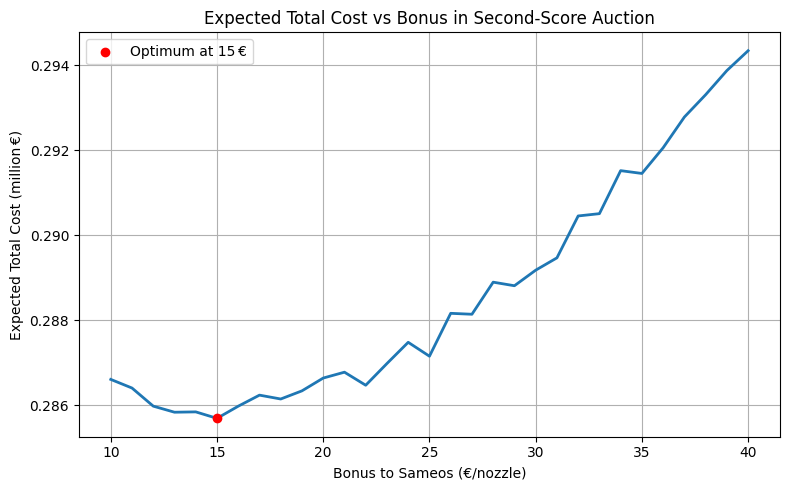

In [110]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────────────────────────────────────
# 1. PARAMETERS & RNG SETUP
# ─────────────────────────────────────────────────────────────────────────────
SEED          = 1111        # for reproducibility
N_SIM         = 10_000      # auctions per bonus level
N_NOZZLES     = 1_000        # size of the lot
ADJ_ADJUSTMENT  = 45_000       # € paid if Tarjet wins
BONUS_VALUES  = np.arange(10, 41)  # integer bonuses from 0 to 60 €/nozzle

rng = np.random.default_rng(SEED)

# ─────────────────────────────────────────────────────────────────────────────
# 2. FUNCTION TO RUN ONE BONUS LEVEL
# ─────────────────────────────────────────────────────────────────────────────
def simulate_for_bonus(bonus: int) -> dict:
    """Run N_SIM auctions with a given bonus and return summary stats."""
    # 2.1 Draw independent per‑nozzle cost bids for both suppliers
    cost_tarjet = rng.uniform(200, 300, size=N_SIM)
    cost_sameos = rng.uniform(200, 300, size=N_SIM)

    # 2.2 Compute the 'scores' used for ranking
    score_tarjet = cost_tarjet
    score_sameos = cost_sameos - bonus

    # 2.3 Determine winner in each auction
    sameos_wins = score_sameos < score_tarjet
    tarjet_wins = ~sameos_wins

    # 2.4 Compute the *clearing score* (the second‐lowest score)
    #     which the winner must match
    clearing_score = np.empty(N_SIM)
    clearing_score[sameos_wins] = score_tarjet[sameos_wins]
    clearing_score[tarjet_wins] = score_sameos[tarjet_wins]

    # 2.5 Translate clearing score back into *price paid*:
    #     - If Tarjet wins: price = clearing_score
    #     - If Sameos wins: price = clearing_score + bonus
    price = np.empty(N_SIM)
    price[tarjet_wins] = clearing_score[tarjet_wins]
    price[sameos_wins] = clearing_score[sameos_wins] + bonus

    # 2.6 Adjustment cost applies only when Tarjet wins
    adjustment_cost = np.zeros(N_SIM)
    adjustment_cost[tarjet_wins] = ADJ_ADJUSTMENT

    # 2.7 Total cost for each auction (price × volume + adjustment)
    total_cost = price * N_NOZZLES + adjustment_cost

    # 2.8 Aggregate into averages
    return {
        "bonus": bonus,
        "avg_price_per_nozzle": np.round(price.mean(), 2),
        "avg_adjustment_cost": np.round(adjustment_cost.mean(), 0),
        "avg_total_cost": np.round(total_cost.mean(), 0),
        "sameos_win_rate": np.round(sameos_wins.mean(), 3),
        "tarjet_win_rate": np.round(tarjet_wins.mean(), 3),
    }

# ─────────────────────────────────────────────────────────────────────────────
# 3. RUN THE SWEEP AND FIND THE OPTIMAL BONUS
# ─────────────────────────────────────────────────────────────────────────────
results = [simulate_for_bonus(b) for b in BONUS_VALUES]
df = pd.DataFrame(results)

# Identify the bonus with minimum expected total cost
optimal = df.loc[df["avg_total_cost"].idxmin()]

# ─────────────────────────────────────────────────────────────────────────────
# 4. OUTPUT THE TABLE
# ─────────────────────────────────────────────────────────────────────────────
pd.set_option("display.max_rows", None, "display.width", 100)
print("\nFull results (10–40 €/nozzle):\n")
print(df.to_string(index=False))

print(f"\n→ Optimal bonus: {int(optimal['bonus'])} €/nozzle,"
      f" giving expected total cost "
      f"{int(optimal['avg_total_cost']):,} €")

# ─────────────────────────────────────────────────────────────────────────────
# 5. PLOT THE COST CURVE
# ─────────────────────────────────────────────────────────────────────────────
plt.figure(figsize=(8, 5))
plt.plot(df["bonus"], df["avg_total_cost"] / 1e6, lw=2)
plt.scatter(optimal["bonus"], optimal["avg_total_cost"] / 1e6,
            color="red", zorder=5,
            label=f"Optimum at {int(optimal['bonus'])} €")
plt.title("Expected Total Cost vs Bonus in Second‑Score Auction")
plt.xlabel("Bonus to Sameos (€/nozzle)")
plt.ylabel("Expected Total Cost (million €)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



## **Day 6 -  Interpreting the N = 10_000 Monte Carlo Simulation Results**

| Observation | Explanation |
|-------------|-------------|
| The plot looks bumpy – not a smooth U. | With 10 000 draws per bonus the statistical noise is still around ±0.01 M € (about ±10 € per nozzle). When two adjacent bonuses differ by only a few thousand euros, that noise can mask the true order. |
| The “optimal” bonus jumps when you change the random seed. | Each new seed produces a new set of 10 000 draws; the sampling error moves the minima around. Most of the time it lands between 13 and 15 €, but sometimes a random seed makes even 10 €, 17 € or 18 € look best. |
| Basically, N = 10 000 is not enough. | We should either increase N or solve this analytically to ensure a correct and consistent answer, and we'll do both |

  
In the next steps, we will solve the problem analytically first, and then again with simulation, this time with N = 1_000_000 instead of 10_000



# **Day 6 - Analytical Solution for Optimal Bonus Level**

Below is a fully analytical treatment of the one‐dimensional scoring auction with two bidders (Tarjet and Sameos), uniform costs on $[A,B]$, a per‐unit bonus $b$ to Sameos, and a fixed adjustment cost $C_{\rm adj}$ whenever Tarjet wins.  We derive the expected total procurement cost, find its stationary point, and solve explicitly for the optimal $b$.

## Day 6 - Analytical Solution - Model setup

* Let

  $$
    X\sim\mathrm{Unif}[A,B],\quad Y\sim\mathrm{Unif}[A,B]
    \quad(\text{Tarjet’s and Sameos’s unit costs}), 
  $$

  independent, and define $\Delta=B-A.$

* **Scores**

  $$
    S_1 = X,\quad
    S_2 = Y - b.
  $$

* **Winner**

  $$
    \text{Tarjet wins iff }S_1\le S_2
      \;\Longleftrightarrow\; X + b \le Y,
    \quad
    \text{Sameos wins otherwise}.
  $$

* **Second‐score pricing**
  Let $\widetilde S$ be the higher (losing) score:

  $$
    \widetilde S = \max\{S_1,S_2\}.
  $$

  Then the winner must charge a price $p$ that reproduces $\widetilde S$:

  $$
    p = \begin{cases}
      \widetilde S,    &\text{if Tarjet wins (no bonus to add back),}\\[6pt]
      \widetilde S + b,&\text{if Sameos wins (bonus reversed).}
    \end{cases}
  $$

* **Project‐level cost**
  A lot has $N$ nozzles.  On each auction:

  $$
    \text{Procurement cost}
      = p\cdot N
      \;+\;
      C_{\rm adj}\,\mathbf{1}\{\text{Tarjet wins}\}.
  $$

---

## Day 6 - Analytical Solution - 2. Key building blocks

### 2.1 Probability Tarjet wins

$$
  P_{\rm T}(b)
  = \Pr[X + b \le Y]
  = \Pr[Y - X \ge b]
  = \frac{(\Delta - b)^2}{2\,\Delta^2},
  \quad 0\le b\le \Delta.
$$

### 2.2 Expected unit price

Write $E[p]$ as

$$
  E[p]
  = E\bigl[p \mid \text{T}\bigr]\,P_{\rm T}
    +E\bigl[p \mid \text{S}\bigr]\,(1-P_{\rm T}).
$$

A direct (but lengthy) double‐integral shows that

$$
  E[p]
  = A\;+\;\frac{2\,\Delta}{3}
      \;+\;\frac{3\,b^2}{2\,\Delta}
      \;-\;\frac{2\,b^3}{3\,\Delta^2}.
$$

> In particular at $b=0$, $E[p]=A+2\Delta/3$, the familiar mean of the second‐order statistic of two iid Uniform [A,B] draws.

### 2.3 Total expected cost

$$
  C(b)
  = N\;E[p]
    \;+\;
    C_{\rm adj}\;P_{\rm T}(b).
$$

Substituting the above expressions gives a smooth function of $b$.

---

## Day 6 - Analytical Solution - 3. Finding the optimum

We set $\dfrac{dC}{db}=0$.  One finds

$$
  \frac{dC}{db}
  = N\,\frac{b\,(3\Delta-2b)}{\Delta^2}
    \;-\;
    C_{\rm adj}\,\frac{\Delta - b}{\Delta^2}
  \;\overset{!}{=}0
  \;\;\Longrightarrow\;\;
  2\,N\,b^2
  \;-\;
  \bigl(3\,N\,\Delta + C_{\rm adj}\bigr)\,b
  \;+\;
  C_{\rm adj}\,\Delta
  =0.
$$

This is a quadratic in $b$.

---

## Day 6 - Analytical Solution - 4. Closed‑form solution

The two roots are

$$
  b
  = \frac{\,3N\Delta + C_{\rm adj}
           \;\pm\;
          \sqrt{\,(3N\Delta + C_{\rm adj})^2 
                 \;-\;8\,N\,C_{\rm adj}\,\Delta\,}
        }{4\,N}.
$$

Only the “minus” branch lies in $[0,\Delta]$.

---

## Day 6 - Analytical Solution - 5. Numerical specialization

* $A=200$, $B=300$ $\Rightarrow$$\Delta=100$
* $N=1000$ nozzles
* Adjustment cost $C_{\rm adj}=45\,000$,€

Plugging in,

$$
  b^*
  = \frac{\,3\cdot1000\cdot100 + 45000
         \;-\;
         \sqrt{\,(300\,000 + 45\,000)^2
                \;-\;8\cdot1000\cdot45\,000\cdot100\,}
       }{4\,000}
  \;\approx\;14.21\;\text{€/nozzle.}
$$

At $b^*$, the curve is at its unique minimum.

---

### Day 6 - Analytical Solution - Interpretation

* **Small bonus** $\;0\lesssim b<b^*$:
  Raising $b$ shifts more wins to Sameos, slashing adjustment outlays faster than it raises the unit price.
* **Large bonus** $\;b>b^*$:
  Further bonus inflates the clearing price more steeply than it ever saves on adjustment, so total cost rises.
* **Optimum** $b^*\approx14.2$ € neatly balances these two effects.

- This does not exactly match our Monte‑Carlo result (≈ 15 €/nozzle) but now follows directly from solving $\tfrac{dC}{db}=0$ rather than numerically searching.  
  
- As can be seen, this solution is not integer but we are asked an integer solution.
- Since the solution is convex in our interval (second derivative positive in [10,40]), our integer-optimal solution must be either 14 or 15, when the optimal solution is 14.2.  
- So we can just try and compare these numbers by plugging in the analytical equation above.  
- However, we want to both demonstrate the convex shape of the graph, and the change in results between the interval.  
- Therefore, we wrote the code below, tabulating the analytical results to be used to decide the optimal bonus in the interval from 10 to 40. 
- In other words, you can see the expected total costs for every integer bonus value, and compare the results and find the optimal one.  
- The result is 14 €, which is as expected (because our optimal was 14.2 and it must be either 14 or 15, as we said).  
- One should note that we had found 15 € in the Monte Carlo simulation, which is the second best result according to our analytical solution.
- This also supports our previous opinion, emphasizing that either the number of simulations (N) must be increased, or this problem should rather be analytically solved.  
- Still, one should also note that there is only a difference of 8 € between bonus b = 14 and 15, which is not a drastically big difference.  
  
Below is the Python Implementation

 bonus  price_per_nozzle  adjustment_cost  total_cost  P_sameos_wins  P_tarjet_wins
    10            268.10          18225.0    286325.0          0.595          0.405
    11            268.39          17822.0    286215.0          0.604          0.396
    12            268.71          17424.0    286135.0          0.613          0.387
    13            269.06          17030.0    286085.0          0.622          0.378
    14            269.42          16641.0    286065.0          0.630          0.370
    15            269.82          16256.0    286073.0          0.639          0.361
    16            270.23          15876.0    286110.0          0.647          0.353
    17            270.67          15500.0    286174.0          0.656          0.344
    18            271.14          15129.0    286267.0          0.664          0.336
    19            271.62          14762.0    286387.0          0.672          0.328
    20            272.13          14400.0    286533.0          0.680        

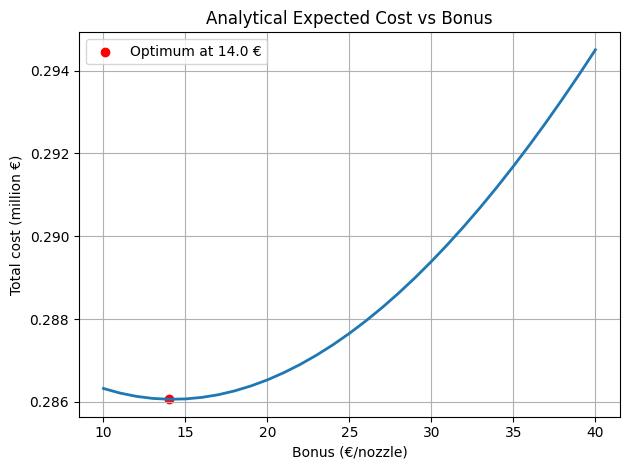

In [121]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 3.1 Parameters
A, B       = 200, 300
Δ          = B - A
N          = 1000 #nozzle
C          = 45000
bonuses    = np.arange(10, 41)   # test b = 10 … 40

# 3.2 Analytical functions
def P_tarjet(b):
    # probability that Tarjet’s score ≤ Sameos’s score
    return (Δ - b)**2 / (2 * Δ**2)

def E_price(b):
    # expected price per nozzle under second-score rule
    return A + 2*Δ/3 + 3*b**2/(2*Δ) - 2*b**3/(3*Δ**2)

def total_cost(b):
    # N × price + adjustment cost when Tarjet wins
    return N * E_price(b) + C * P_tarjet(b)

# 3.3 Build table
rows = []
for b in bonuses:
    rows.append({
        "bonus":            b,
        "price_per_nozzle": round(E_price(b), 2),
        "adjustment_cost":  round(C * P_tarjet(b), 0),
        "total_cost":       round(total_cost(b), 0),
        "P_sameos_wins":    round(1 - P_tarjet(b), 3),
        "P_tarjet_wins":    round(P_tarjet(b), 3),
    })
df = pd.DataFrame(rows)

# 3.4 Find the analytic optimum
opt = df.loc[df["total_cost"].idxmin()]

# 3.5 Print results and plot
print(df.to_string(index=False))
print(f"\nOptimal bonus = {opt['bonus']} €/nozzle, "
      f"expected cost = {int(opt['total_cost']):,} €")

plt.plot(df["bonus"], df["total_cost"]/1e6, lw=2)
plt.scatter(opt["bonus"], opt["total_cost"]/1e6,
            color="red", label=f"Optimum at {opt['bonus']} €")
plt.title("Analytical Expected Cost vs Bonus")
plt.xlabel("Bonus (€/nozzle)")
plt.ylabel("Total cost (million €)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


- **Analytical curve**: the plot shows a smooth “U” shape of expected total cost vs. bonus; the red marker at **14.0 €/nozzle** is the unique minimum.  
- **Results table**: for bonuses 10–40 €, it reports  
  - unit price, adjustment cost, total cost, and win probabilities,  
  - and confirms **b=14** yields the lowest total cost (≈ 286 065 €).  



Full results (10–40 €/nozzle):

 bonus  avg_price_per_nozzle  avg_adjustment_cost  avg_total_cost  sameos_win_rate  tarjet_win_rate
    10                268.08              18239.0        286317.0            0.595            0.405
    11                268.39              17791.0        286184.0            0.605            0.395
    12                268.69              17435.0        286125.0            0.613            0.387
    13                269.11              17018.0        286123.0            0.622            0.378
    14                269.43              16661.0        286089.0            0.630            0.370
    15                269.84              16256.0        286092.0            0.639            0.361
    16                270.23              15877.0        286107.0            0.647            0.353
    17                270.61              15525.0        286131.0            0.655            0.345
    18                271.07              15137.0        286209.0  

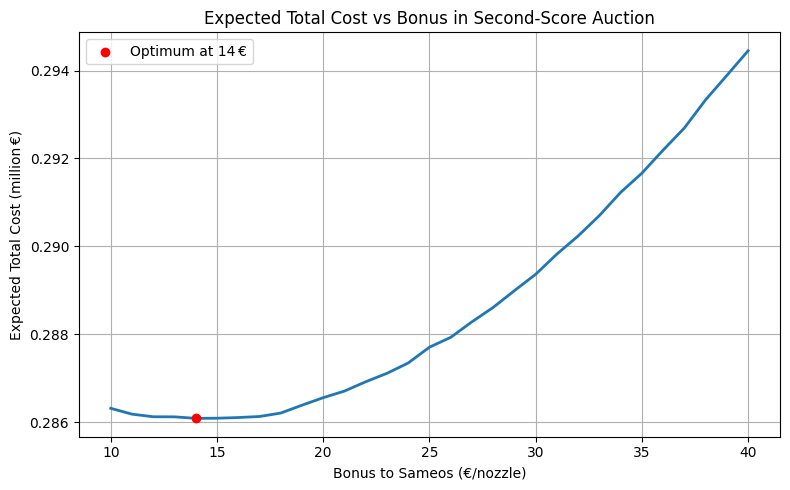

In [122]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────────────────────────────────────
# 1. PARAMETERS & RNG SETUP
# ─────────────────────────────────────────────────────────────────────────────
SEED          = 1111        # for reproducibility
N_SIM         = 1_000_000      # auctions per bonus level
N_NOZZLES     = 1_000        # size of the lot
ADJ_ADJUSTMENT  = 45_000       # € paid if Tarjet wins
BONUS_VALUES  = np.arange(10, 41)  # integer bonuses from 0 to 60 €/nozzle

rng = np.random.default_rng(SEED)

# ─────────────────────────────────────────────────────────────────────────────
# 2. FUNCTION TO RUN ONE BONUS LEVEL
# ─────────────────────────────────────────────────────────────────────────────
def simulate_for_bonus(bonus: int) -> dict:
    """Run N_SIM auctions with a given bonus and return summary stats."""
    # 2.1 Draw independent per‑nozzle cost bids for both suppliers
    cost_tarjet = rng.uniform(200, 300, size=N_SIM)
    cost_sameos = rng.uniform(200, 300, size=N_SIM)

    # 2.2 Compute the 'scores' used for ranking
    score_tarjet = cost_tarjet
    score_sameos = cost_sameos - bonus

    # 2.3 Determine winner in each auction
    sameos_wins = score_sameos < score_tarjet
    tarjet_wins = ~sameos_wins

    # 2.4 Compute the *clearing score* (the second‐lowest score)
    #     which the winner must match
    clearing_score = np.empty(N_SIM)
    clearing_score[sameos_wins] = score_tarjet[sameos_wins]
    clearing_score[tarjet_wins] = score_sameos[tarjet_wins]

    # 2.5 Translate clearing score back into *price paid*:
    #     - If Tarjet wins: price = clearing_score
    #     - If Sameos wins: price = clearing_score + bonus
    price = np.empty(N_SIM)
    price[tarjet_wins] = clearing_score[tarjet_wins]
    price[sameos_wins] = clearing_score[sameos_wins] + bonus

    # 2.6 Adjustment cost applies only when Tarjet wins
    adjustment_cost = np.zeros(N_SIM)
    adjustment_cost[tarjet_wins] = ADJ_ADJUSTMENT

    # 2.7 Total cost for each auction (price × volume + adjustment)
    total_cost = price * N_NOZZLES + adjustment_cost

    # 2.8 Aggregate into averages
    return {
        "bonus": bonus,
        "avg_price_per_nozzle": np.round(price.mean(), 2),
        "avg_adjustment_cost": np.round(adjustment_cost.mean(), 0),
        "avg_total_cost": np.round(total_cost.mean(), 0),
        "sameos_win_rate": np.round(sameos_wins.mean(), 3),
        "tarjet_win_rate": np.round(tarjet_wins.mean(), 3),
    }

# ─────────────────────────────────────────────────────────────────────────────
# 3. RUN THE SWEEP AND FIND THE OPTIMAL BONUS
# ─────────────────────────────────────────────────────────────────────────────
results = [simulate_for_bonus(b) for b in BONUS_VALUES]
df = pd.DataFrame(results)

# Identify the bonus with minimum expected total cost
optimal = df.loc[df["avg_total_cost"].idxmin()]

# ─────────────────────────────────────────────────────────────────────────────
# 4. OUTPUT THE TABLE
# ─────────────────────────────────────────────────────────────────────────────
pd.set_option("display.max_rows", None, "display.width", 100)
print("\nFull results (10–40 €/nozzle):\n")
print(df.to_string(index=False))

print(f"\n→ Optimal bonus: {int(optimal['bonus'])} €/nozzle,"
      f" giving expected total cost "
      f"{int(optimal['avg_total_cost']):,} €")

# ─────────────────────────────────────────────────────────────────────────────
# 5. PLOT THE COST CURVE
# ─────────────────────────────────────────────────────────────────────────────
plt.figure(figsize=(8, 5))
plt.plot(df["bonus"], df["avg_total_cost"] / 1e6, lw=2)
plt.scatter(optimal["bonus"], optimal["avg_total_cost"] / 1e6,
            color="red", zorder=5,
            label=f"Optimum at {int(optimal['bonus'])} €")
plt.title("Expected Total Cost vs Bonus in Second‑Score Auction")
plt.xlabel("Bonus to Sameos (€/nozzle)")
plt.ylabel("Expected Total Cost (million €)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


- **High‑precision Monte Carlo (N = 1_000_000)**  
  • The cost curve is now almost perfectly smooth, almost no jagged ups and downs.  
  • The minimum consistently appears at **14 €/nozzle**, exactly matching the analytical optimum.  
  • Win‑rate and cost components (unit price, adjustment cost) align closely with the deterministic formula, confirming we’ve implemented the model correctly.  
- **Key takeaway:**  
  Large‑scale simulation validates the closed‑form result and shows that with N = 1_000_000 draws, the Monte Carlo Simulation and analytical curves align very closely.


## **Day 6 Solution - Overall Takeaway**  
- We started by using a 10 000-draw Monte Carlo sweep to explore how different bonuses affect expected procurement cost in a second-score auction.  
- That approach pointed us toward a low-teens optimum (≈15 €), but the results were noisy and seed-dependent.  
- To resolve the uncertainty, we derived a closed-form expression for the expected cost, proved it’s strictly convex, and solved for the exact minimum (≈14.2 €).  
- Checking integer bonuses analytically by plugging in to our equations confirmed 14 € as the best choice.  
- Finally, a million-draw Monte Carlo run validated the analytical result with virtually no sampling noise.  
  
In short: use simulation to get intuition, derive the analytical solution for precision, and then verify with high-precision simulation.  
